<a href="https://colab.research.google.com/github/Takayoshi-code/nanoGPT-class/blob/master/for_class2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# @title 【STEP1】 nanoGPT環境をgitHubからdownloadする。
# ===== 安全版 =====

import os

print("===== Step 0: /content に移動 =====")
%cd /content

print("===== Step 1: クリーン =====")
!rm -rf nanoGPT
!rm -f master.zip

print("===== Step 2: ライブラリ =====")
!pip install -q sentencepiece datasets tqdm

print("===== Step 3: nanoGPT取得 =====")

!wget -q https://github.com/Takayoshi-code/nanoGPT-class/archive/refs/heads/master.zip
!unzip -q master.zip
!mv nanoGPT-class-master nanoGPT

print("===== Step 4: 移動 =====")
%cd /content/nanoGPT

print("===== Step 5: 確認 =====")
!ls

===== Step 0: /content に移動 =====
/content
===== Step 1: クリーン =====
===== Step 2: ライブラリ =====
===== Step 3: nanoGPT取得 =====
===== Step 4: 移動 =====
/content/nanoGPT
===== Step 5: 確認 =====
assets		  LICENSE			 sample.py
bench.py	  model_class2.py		 scaling_laws.ipynb
config		  model.py			 train.py
configurator.py   nanoGPT_Aozora_tiny.ipynb	 train_with_history.py
data		  nanoGPT_tutorial_class2.ipynb  transformer_sizing.ipynb
for_class3.ipynb  README.md


In [6]:
# @title 【STEP2】 Tokenizerの実行　入力コーパスは「吾輩は猫である。名前はまだない。どこで生れたかとんと見当がつかぬ。」　を100回繰り返したもの。学習用データと検証用データに同じ文章が登場するため、いわゆるData leakageが起きている状況ですが、今回はそれには目をつぶります。なお、語彙数は事前に16個（先週にくらべて非常に少ない。）設定しています。
# ============================================================
# prepare.py
# 教材用：SentencePieceを使わない最小トークナイザ
# ============================================================
from pathlib import Path
import os
import time
import pickle
import threading
import numpy as np

CORPUS_DIR = Path("/content/nanoGPT/corpus")
CORPUS_DIR.mkdir(parents=True, exist_ok=True)

INPUT = CORPUS_DIR / "input.txt"

INPUT.write_text(
    "吾輩は猫である。名前はまだない。どこで生れたかとんと見当がつかぬ。",
    encoding="utf-8"
)

print("作成:", INPUT)
print("内容:", INPUT.read_text(encoding="utf-8"))

BASE = Path("/content/nanoGPT")
OUT_DIR = BASE / "data" / "jp"
INPUT = BASE / "corpus" / "input.txt"

print("BASE    =", BASE)
print("INPUT   =", INPUT)
print("OUT_DIR =", OUT_DIR)
print("INPUT exists =", INPUT.exists())

# ------------------------------------------------------------
# 語彙（教材用）
# ------------------------------------------------------------

vocab = [
    "吾輩",
    "である",
    "名前",
    "まだ",
    "ない",
    "猫",
    "は",
    "。",
    "どこ",
    "で",
    "生れた",
    "か",
    "とんと",
    "見当",
    "が",
    "つかぬ"
]

# 最長一致のため長い順に並べる
#vocab = sorted(vocab, key=len, reverse=True)

stoi = {w: i for i, w in enumerate(vocab)}
itos = {i: w for w, i in stoi.items()}

print("Vocabulary")
for w, i in stoi.items():
    print(f"{i:2d} : {w}")

# ------------------------------------------------------------
# Heart Beat
# ------------------------------------------------------------

running = True

def heartbeat():
    while running:
        print("ただいま計算中...", flush=True)
        time.sleep(5)

thread = threading.Thread(target=heartbeat)
thread.start()

# ------------------------------------------------------------
# Tokenizer
# ------------------------------------------------------------

def tokenize(text):

    ids = []
    pos = 0

    while pos < len(text):

        if text[pos].isspace():
            pos += 1
            continue

        matched = False

        for token in vocab:

            if text.startswith(token, pos):
                ids.append(stoi[token])
                pos += len(token)
                matched = True
                break

        if not matched:
            raise ValueError(
                f"未知語: '{text[pos]}' (位置 {pos})\n"
                "vocabへ追加してください。"
            )

    return ids

# ------------------------------------------------------------
# Main
# ------------------------------------------------------------

try:

    t0 = time.time()

    with open(INPUT, encoding="utf-8") as f:
        text = f.read()

    print("\n入力")
    print(text)

    # 教材用なので100回繰り返す
    repeat = 100

    ids = tokenize(text) * repeat

    print()
    print("元トークン数 :", len(ids) // repeat)
    print("繰り返し回数 :", repeat)
    print("総トークン数 :", len(ids))

    print("\nToken IDs")
    print(ids)

    print("\nToken列")

    for i in ids:
        print(f"{i:2d} : {itos[i]}")

    # --------------------------------------------------------
    # train / val
    # --------------------------------------------------------

    n = int(len(ids) * 0.9)

    train_ids = np.array(ids[:n], dtype=np.uint16)
    val_ids = np.array(ids[n:], dtype=np.uint16)

    os.makedirs(OUT_DIR, exist_ok=True)

    train_ids.tofile(os.path.join(OUT_DIR, "train.bin"))
    val_ids.tofile(os.path.join(OUT_DIR, "val.bin"))

    # --------------------------------------------------------
    # meta.pkl
    # --------------------------------------------------------

    meta = {
        "vocab_size": len(vocab),
        "vocab": vocab,
        "stoi": stoi,
        "itos": itos,
    }

    with open(os.path.join(OUT_DIR, "meta.pkl"), "wb") as f:
        pickle.dump(meta, f)

    print()
    print("保存完了")
    print(" train.bin")
    print(" val.bin")
    print(" meta.pkl")

    print()
    print(f"vocab_size = {len(vocab)}")

    print("\n復号")

    print(" ".join(itos[i] for i in train_ids))

    print(f"\n処理時間 {time.time()-t0:.2f} 秒")

finally:

    running = False
    thread.join()

作成: /content/nanoGPT/corpus/input.txt
内容: 吾輩は猫である。名前はまだない。どこで生れたかとんと見当がつかぬ。
BASE    = /content/nanoGPT
INPUT   = /content/nanoGPT/corpus/input.txt
OUT_DIR = /content/nanoGPT/data/jp
INPUT exists = True
Vocabulary
 0 : 吾輩
 1 : である
 2 : 名前
 3 : まだ
 4 : ない
 5 : 猫
 6 : は
 7 : 。
 8 : どこ
 9 : で
10 : 生れた
11 : か
12 : とんと
13 : 見当
14 : が
15 : つかぬ
ただいま計算中...

入力
吾輩は猫である。名前はまだない。どこで生れたかとんと見当がつかぬ。

元トークン数 : 19
繰り返し回数 : 100
総トークン数 : 1900

Token IDs
[0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 15, 7, 0, 6, 5, 1, 7, 2, 6, 3, 4, 7, 8, 9, 10, 11, 12, 13, 14, 

nanoGPT Training
Parameters        = 336
Vocab size        = 16
Model             = 1 layer / 1 head / 4 dim
Current iteration = 15000 / 15000
Train loss        = 0.0917
Val loss          = 0.0908
Best val loss     = 0.0892
Best iteration    = 14600


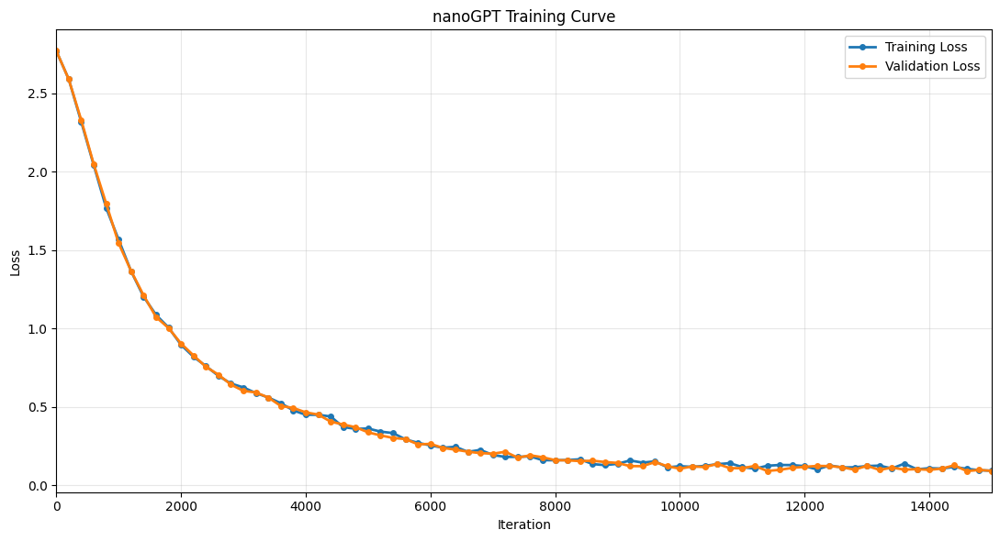

Training finished normally.
Parameters        : 336
Last iteration    : 15000
Train loss        : 0.0917
Val loss          : 0.0908
Best val loss     : 0.0892
Best iteration    : 14600


In [9]:
# @title 【STEP3】  nanoGPTの学習を実行させる。最初はblock_size=4にした場合とblock_size=5にした場合で学習させてみる。
# ============================================================
# nanoGPT Training + Real-time Training Curve
# Training Loss / Validation Loss のみ表示
# Model parameter count も表示
# ============================================================
import os
import re
import pickle
import subprocess
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from model import GPT, GPTConfig

# ============================================================
# Settings
# ============================================================
BASE = "/content/nanoGPT"
DATASET = "jp"
HISTORY = os.path.join(BASE, "history")

N_LAYER = 1
N_HEAD = 1
N_EMBD = 4
BLOCK_SIZE = 5  #4と5で試してみよう。
BATCH_SIZE = 5
MAX_ITERS = 15000
EVAL_INTERVAL = 200
EVAL_ITERS = 20
LEARNING_RATE = 5e-4
MIN_LR = 5e-5
WARMUP_ITERS = 100

os.makedirs(HISTORY, exist_ok=True)
os.chdir(BASE)

# ============================================================
# Delete old history files
# ============================================================
for filename in os.listdir(HISTORY):
    if filename.endswith(".pt"):
        os.remove(os.path.join(HISTORY, filename))

# ============================================================
# Select training script
# ============================================================
TRAIN_HISTORY = os.path.join(BASE, "train_with_history.py")
TRAIN_NORMAL = os.path.join(BASE, "train.py")

if os.path.exists(TRAIN_HISTORY):
    TRAIN_SCRIPT = "train_with_history.py"
elif os.path.exists(TRAIN_NORMAL):
    TRAIN_SCRIPT = "train.py"
else:
    raise FileNotFoundError(
        "train_with_history.py and train.py were not found."
    )

# ============================================================
# Get vocab_size
# ============================================================
meta_path = os.path.join(BASE, "data", DATASET, "meta.pkl")

if not os.path.exists(meta_path):
    raise FileNotFoundError(
        f"meta.pkl was not found: {meta_path}"
    )

with open(meta_path, "rb") as f:
    meta = pickle.load(f)

if "vocab_size" not in meta:
    raise KeyError(
        "vocab_size was not found in meta.pkl"
    )

VOCAB_SIZE = meta["vocab_size"]

# ============================================================
# Create temporary model for parameter count
# ============================================================
config = GPTConfig(
    block_size=BLOCK_SIZE,
    vocab_size=VOCAB_SIZE,
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_embd=N_EMBD,
    dropout=0.0,
    bias=True
)

model_for_count = GPT(config)

TOTAL_PARAMS = sum(
    p.numel() for p in model_for_count.parameters()
)

TRAINABLE_PARAMS = sum(
    p.numel()
    for p in model_for_count.parameters()
    if p.requires_grad
)

PARAM_SIZE_FP32_MB = TOTAL_PARAMS * 4 / 1024**2

del model_for_count

# ============================================================
# Model information
# ============================================================
print("=" * 65)
print("nanoGPT Model Information")
print("=" * 65)
print(f"training script      = {TRAIN_SCRIPT}")
print(f"dataset              = {DATASET}")
print(f"vocab size           = {VOCAB_SIZE:,}")
print(f"block size           = {BLOCK_SIZE}")
print(f"number of layers     = {N_LAYER}")
print(f"number of heads      = {N_HEAD}")
print(f"embedding dimension  = {N_EMBD}")
print(f"number of parameters = {TOTAL_PARAMS:,}")
print(f"trainable parameters = {TRAINABLE_PARAMS:,}")
print(f"parameter size FP32  = {PARAM_SIZE_FP32_MB:.4f} MB")
print("=" * 65)

# ============================================================
# Training command
# ============================================================
cmd = [
    "python", "-u", TRAIN_SCRIPT,
    f"--dataset={DATASET}",
    "--device=cpu",
    "--compile=False",
    "--dtype=float32",
    "--init_from=scratch",
    f"--n_layer={N_LAYER}",
    f"--n_head={N_HEAD}",
    f"--n_embd={N_EMBD}",
    "--bias=True",
    "--dropout=0.0",
    f"--batch_size={BATCH_SIZE}",
    "--gradient_accumulation_steps=1",
    f"--block_size={BLOCK_SIZE}",
    f"--max_iters={MAX_ITERS}",
    f"--lr_decay_iters={MAX_ITERS}",
    f"--warmup_iters={WARMUP_ITERS}",
    f"--learning_rate={LEARNING_RATE}",
    f"--min_lr={MIN_LR}",
    f"--eval_interval={EVAL_INTERVAL}",
    f"--eval_iters={EVAL_ITERS}",
    "--log_interval=20",
]

# ============================================================
# Storage
# ============================================================
eval_steps = []
train_losses = []
val_losses = []
current_iteration = 0

# step 200: train loss 1.2345, val loss 1.3456
eval_pattern = re.compile(
    r"step\s+(\d+):\s+train loss\s+"
    r"([0-9.eE+-]+),\s+val loss\s+([0-9.eE+-]+)"
)

# iter 200: loss 1.2345, time ...
# iteration loss は保存・描画しない
iter_pattern = re.compile(
    r"iter\s+(\d+):"
)

# ============================================================
# Draw graph
# ============================================================
def draw_graph():
    clear_output(wait=True)

    print("=" * 65)
    print("nanoGPT Training")
    print("=" * 65)
    print(f"Parameters        = {TOTAL_PARAMS:,}")
    print(f"Vocab size        = {VOCAB_SIZE:,}")
    print(f"Model             = {N_LAYER} layer / "
          f"{N_HEAD} head / {N_EMBD} dim")
    print(f"Current iteration = {current_iteration} / {MAX_ITERS}")

    if len(eval_steps) == 0:
        print("Waiting for first validation evaluation...")
        print("=" * 65)
        return

    print(f"Train loss        = {train_losses[-1]:.4f}")
    print(f"Val loss          = {val_losses[-1]:.4f}")

    best_index = val_losses.index(min(val_losses))
    print(f"Best val loss     = {val_losses[best_index]:.4f}")
    print(f"Best iteration    = {eval_steps[best_index]}")
    print("=" * 65)

    plt.figure(figsize=(11, 6))

    # Training Loss
    plt.plot(
        eval_steps,
        train_losses,
        marker="o",
        markersize=4,
        linewidth=2,
        label="Training Loss"
    )

    # Validation Loss
    plt.plot(
        eval_steps,
        val_losses,
        marker="o",
        markersize=4,
        linewidth=2,
        label="Validation Loss"
    )

    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("nanoGPT Training Curve")
    plt.grid(True, alpha=0.3)
    plt.legend()

    # 横軸を1000 iteration単位で自動拡張
    current_step = eval_steps[-1]
    xmax = ((current_step // 1000) + 1) * 1000
    xmax = max(1000, xmax)
    xmax = min(MAX_ITERS, xmax)
    plt.xlim(0, xmax)

    plt.tight_layout()
    plt.show()

# ============================================================
# Start training
# ============================================================
print("Starting nanoGPT...")

process = subprocess.Popen(
    cmd,
    cwd=BASE,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

# ============================================================
# Monitor training
# ============================================================
try:
    for line in process.stdout:
        line = line.rstrip()

        # Evaluation result
        match_eval = eval_pattern.search(line)

        if match_eval:
            step = int(match_eval.group(1))
            train_loss = float(match_eval.group(2))
            val_loss = float(match_eval.group(3))

            eval_steps.append(step)
            train_losses.append(train_loss)
            val_losses.append(val_loss)
            current_iteration = step

            draw_graph()
            continue

        # Current iteration only
        match_iter = iter_pattern.search(line)

        if match_iter:
            current_iteration = int(match_iter.group(1))

        # 最初の評価までは起動ログ・エラーを表示
        if len(eval_steps) == 0:
            print(line)

except KeyboardInterrupt:
    print("Training interrupted.")
    process.terminate()

finally:
    if process.stdout is not None:
        process.stdout.close()

    return_code = process.wait()

# ============================================================
# Final graph
# ============================================================
draw_graph()

# ============================================================
# Final result
# ============================================================
print("=" * 65)

if return_code == 0:
    print("Training finished normally.")
else:
    print(f"Training stopped with error. return code = {return_code}")

if len(eval_steps) > 0:
    best_index = val_losses.index(min(val_losses))

    print(f"Parameters        : {TOTAL_PARAMS:,}")
    print(f"Last iteration    : {eval_steps[-1]}")
    print(f"Train loss        : {train_losses[-1]:.4f}")
    print(f"Val loss          : {val_losses[-1]:.4f}")
    print(f"Best val loss     : {val_losses[best_index]:.4f}")
    print(f"Best iteration    : {eval_steps[best_index]}")

print("=" * 65)

Japanese font = /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc
device     = cuda
checkpoint = /content/nanoGPT/out/ckpt.pt
meta.pkl   = /content/nanoGPT/data/jp/meta.pkl
meta.pkl keys = ['vocab_size', 'vocab', 'stoi', 'itos']
Vocabulary size = 16
Loading checkpoint...
checkpoint keys = ['model', 'optimizer', 'model_args', 'iter_num', 'best_val_loss', 'config']
Model configuration
n_layer             : 1
n_head              : 1
n_embd              : 4
block_size          : 4
bias                : True
vocab_size          : 16
dropout             : 0.0
number of parameters: 0.00M
number of parameters: 332
number of parameters: 0.33K

TOKEN-BY-TOKEN NEXT TOKEN PROBABILITY

------------------------------------------------------------
Step 1
Input      : 吾輩
Prediction : は
Probability: 0.988913
------------------------------------------------------------


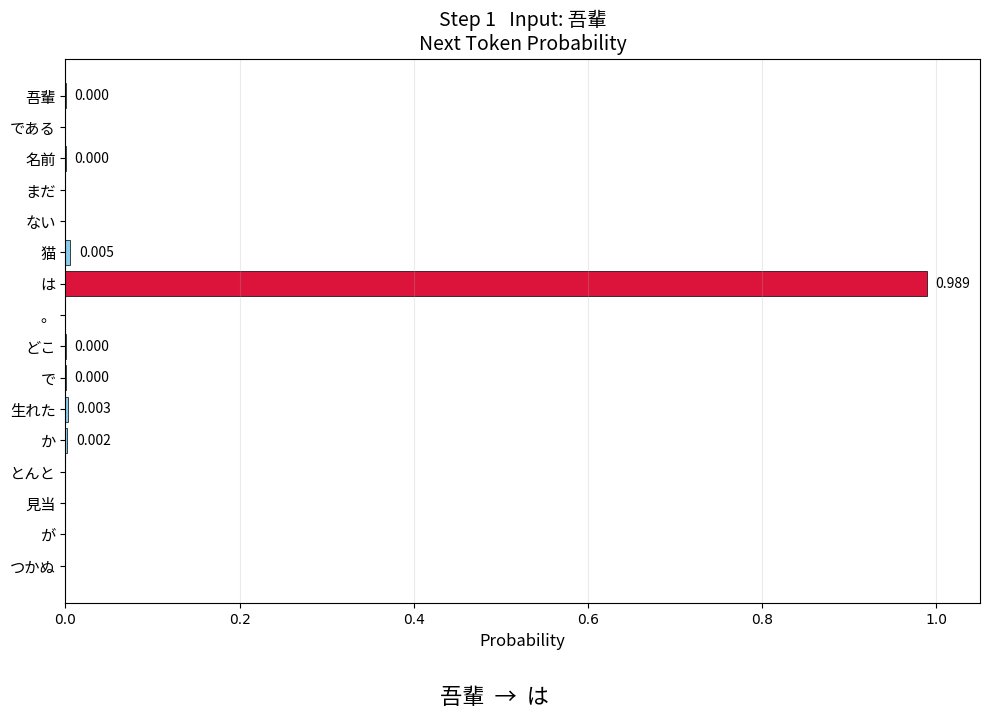


------------------------------------------------------------
Step 2
Input      : 吾輩 は
Prediction : 猫
Probability: 0.526958
------------------------------------------------------------


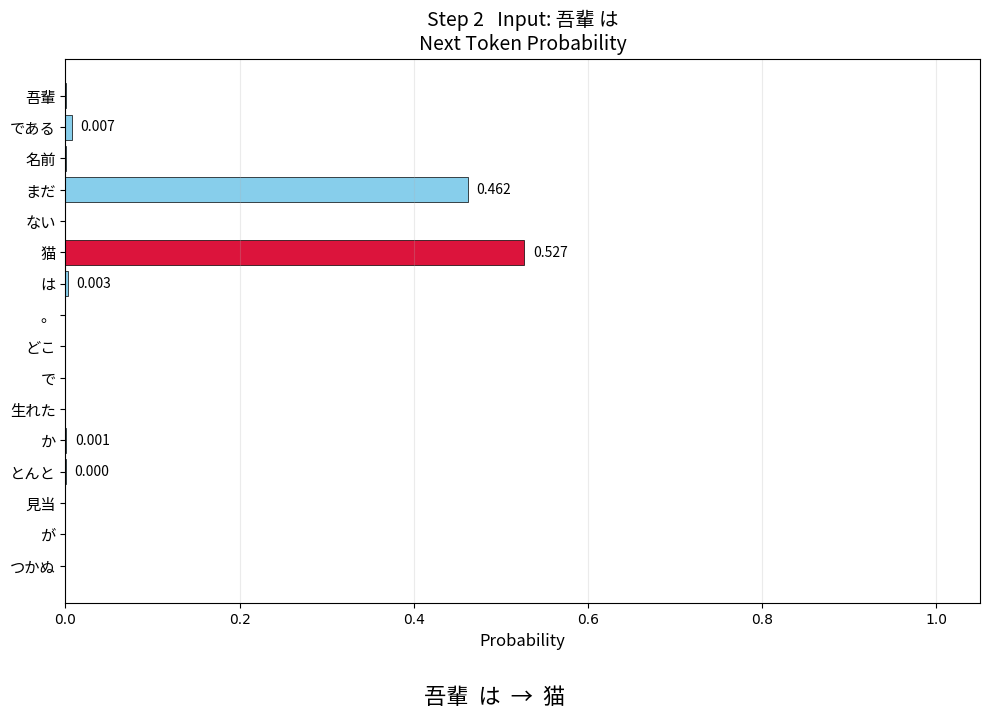


------------------------------------------------------------
Step 3
Input      : 吾輩 は 猫
Prediction : である
Probability: 0.985777
------------------------------------------------------------


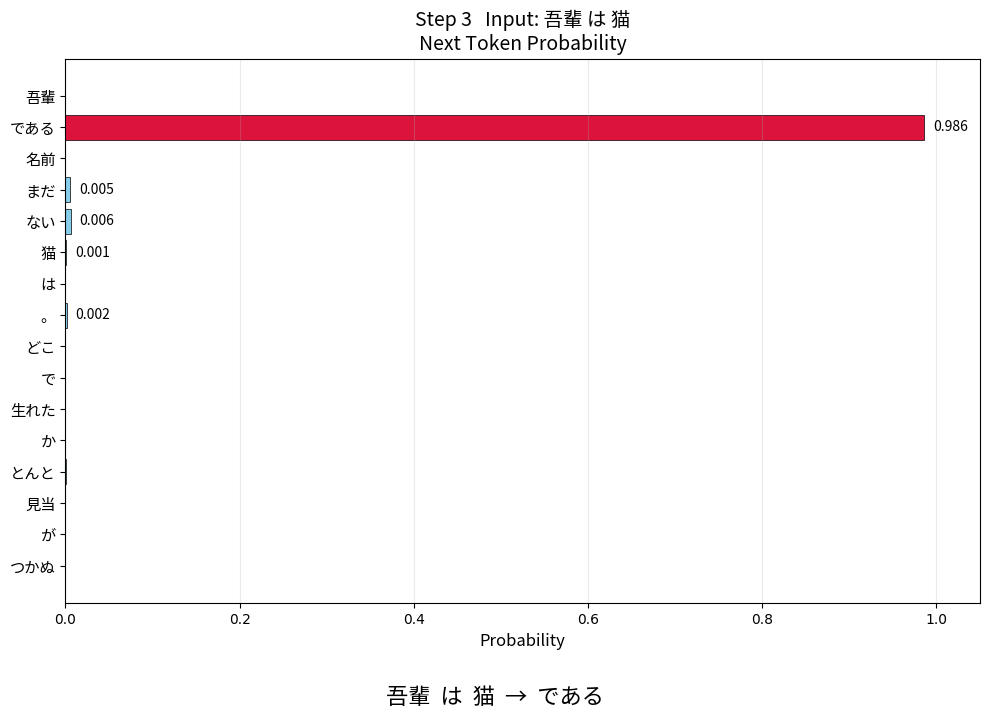


------------------------------------------------------------
Step 4
Input      : 吾輩 は 猫 である
Prediction : 。
Probability: 0.993545
------------------------------------------------------------


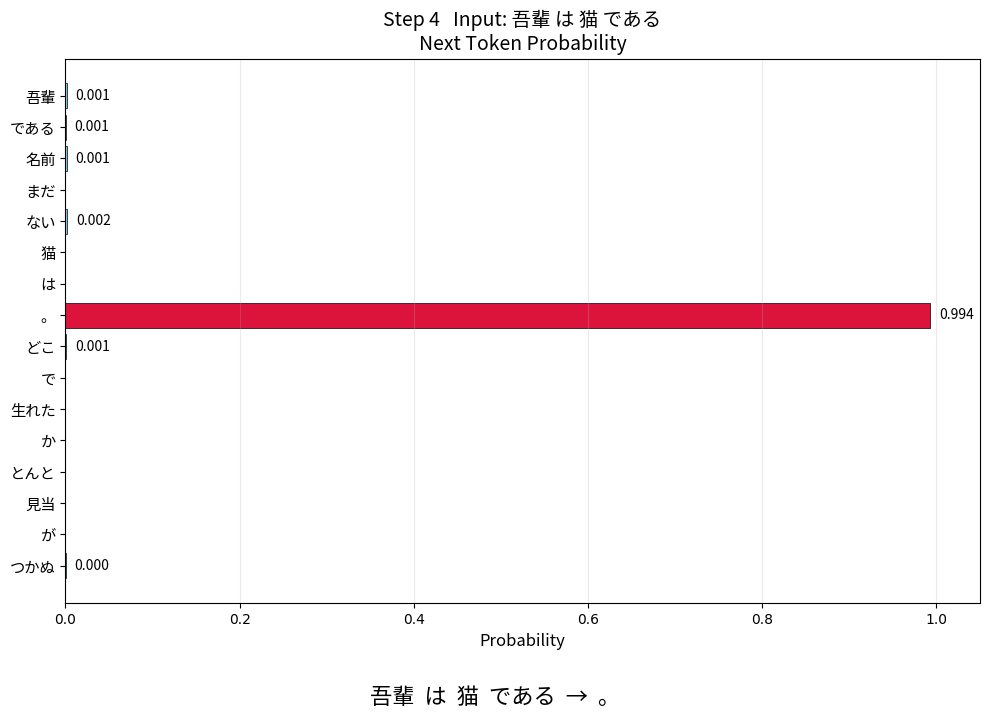


------------------------------------------------------------
Step 5
Input      : 吾輩 は 猫 である 。
Prediction : どこ
Probability: 0.333511
------------------------------------------------------------


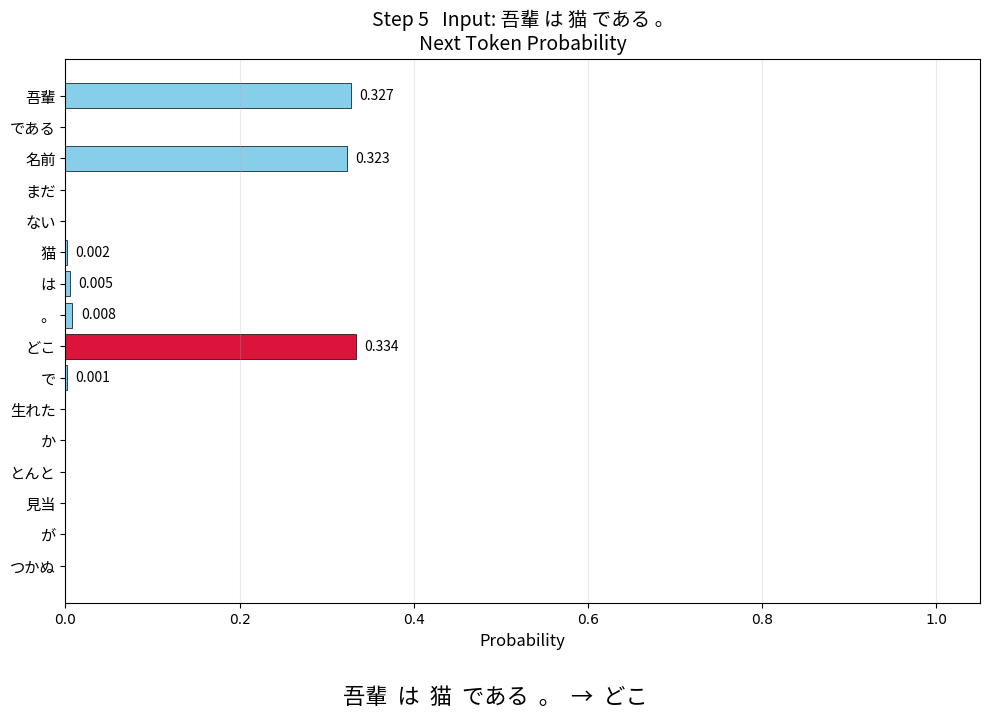


------------------------------------------------------------
Step 6
Input      : 吾輩 は 猫 である 。 どこ
Prediction : で
Probability: 0.983100
------------------------------------------------------------


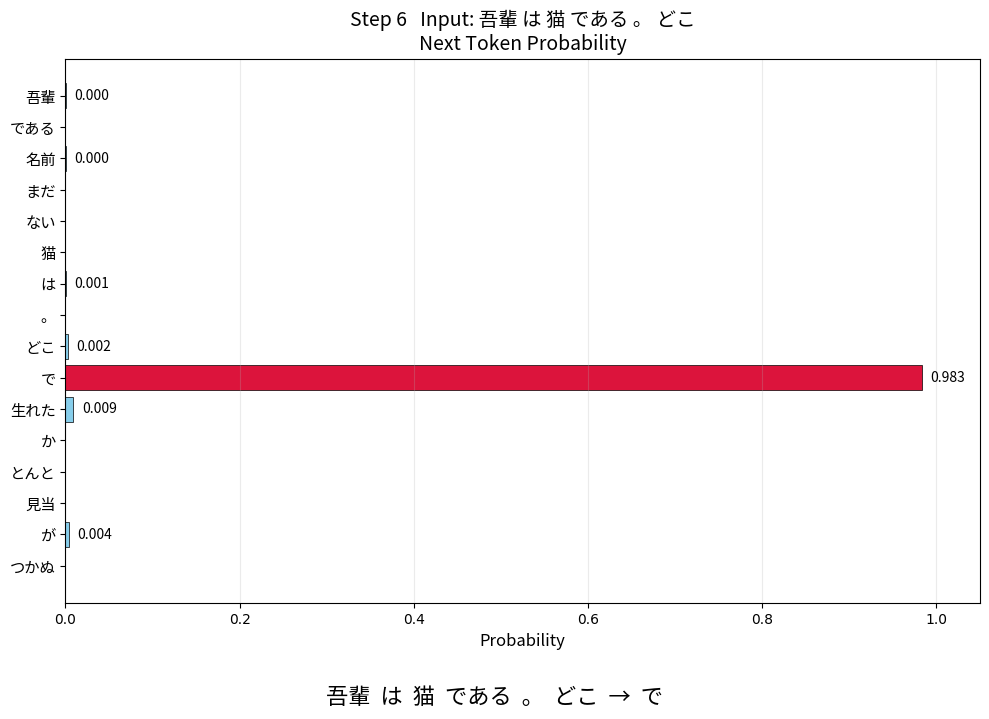


------------------------------------------------------------
Step 7
Input      : 吾輩 は 猫 である 。 どこ で
Prediction : 生れた
Probability: 0.994177
------------------------------------------------------------


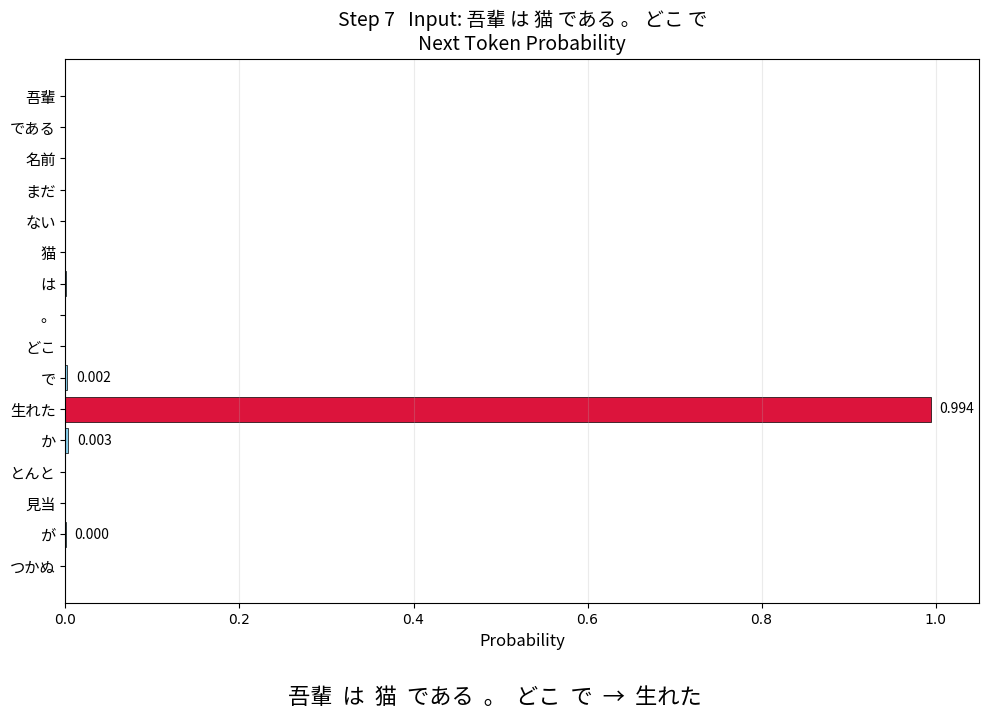


------------------------------------------------------------
Step 8
Input      : 吾輩 は 猫 である 。 どこ で 生れた
Prediction : か
Probability: 0.986351
------------------------------------------------------------


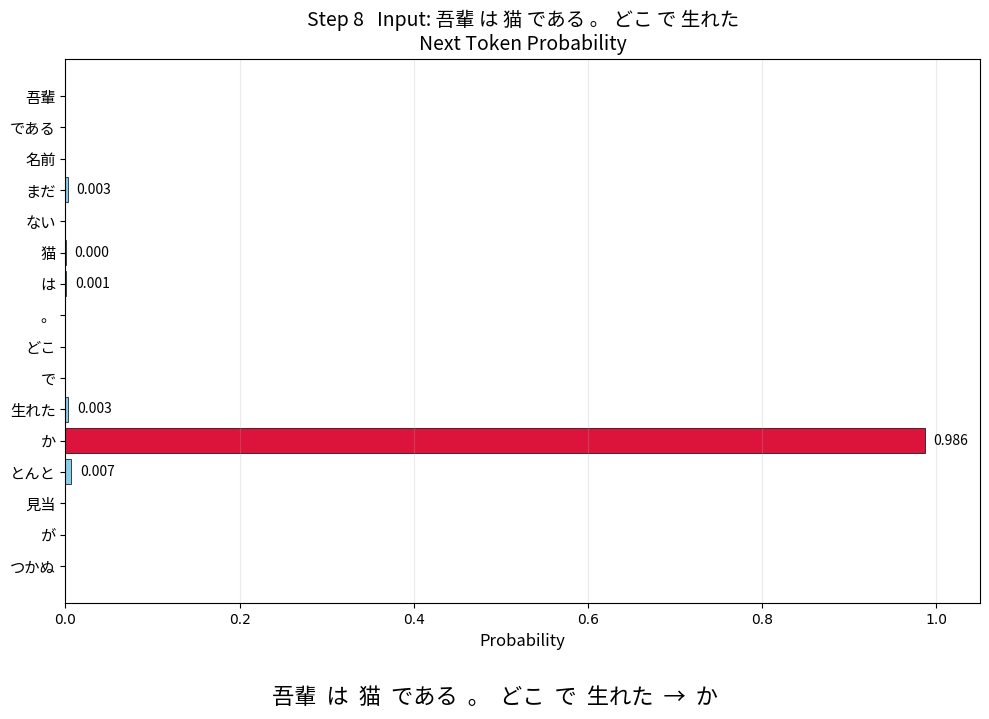


------------------------------------------------------------
Step 9
Input      : 吾輩 は 猫 である 。 どこ で 生れた か
Prediction : とんと
Probability: 0.992117
------------------------------------------------------------


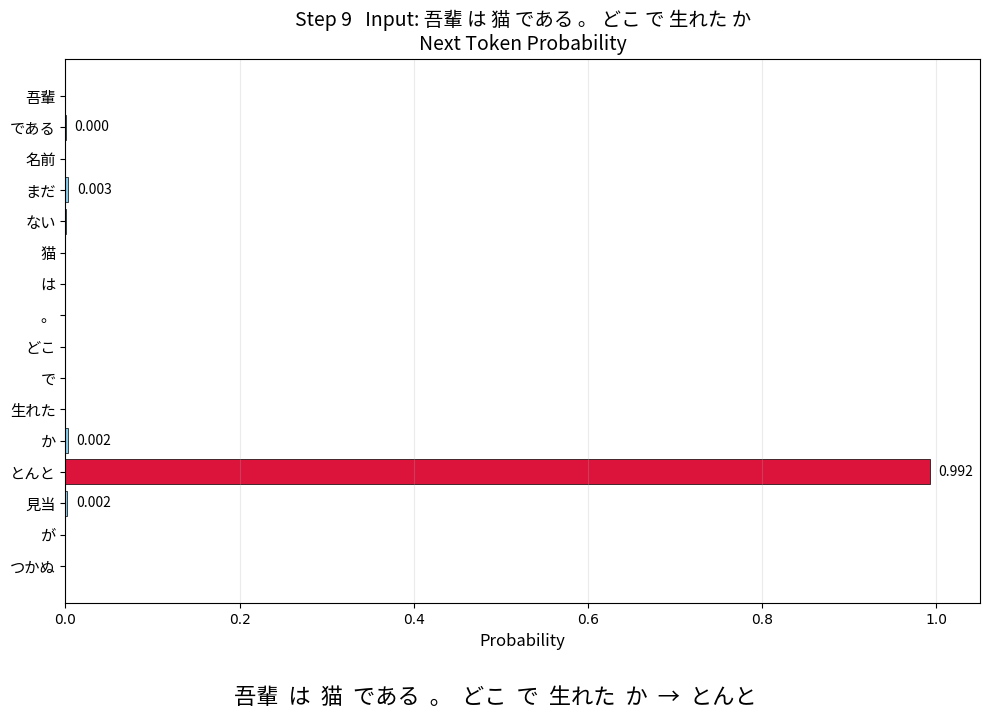


------------------------------------------------------------
Step 10
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと
Prediction : 見当
Probability: 0.988604
------------------------------------------------------------


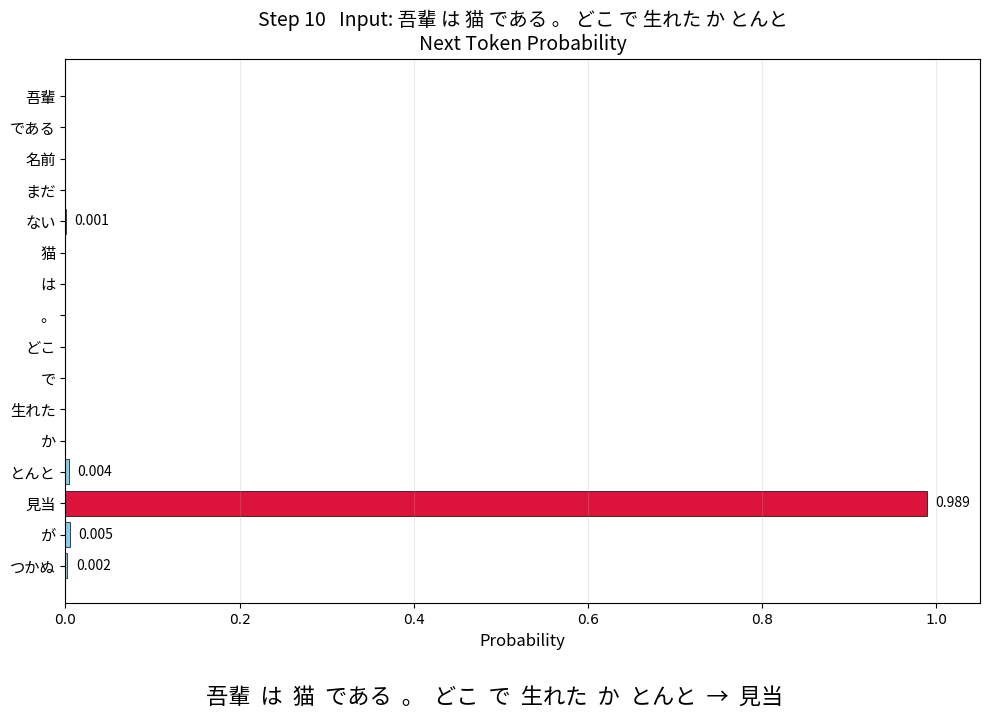


------------------------------------------------------------
Step 11
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当
Prediction : が
Probability: 0.983597
------------------------------------------------------------


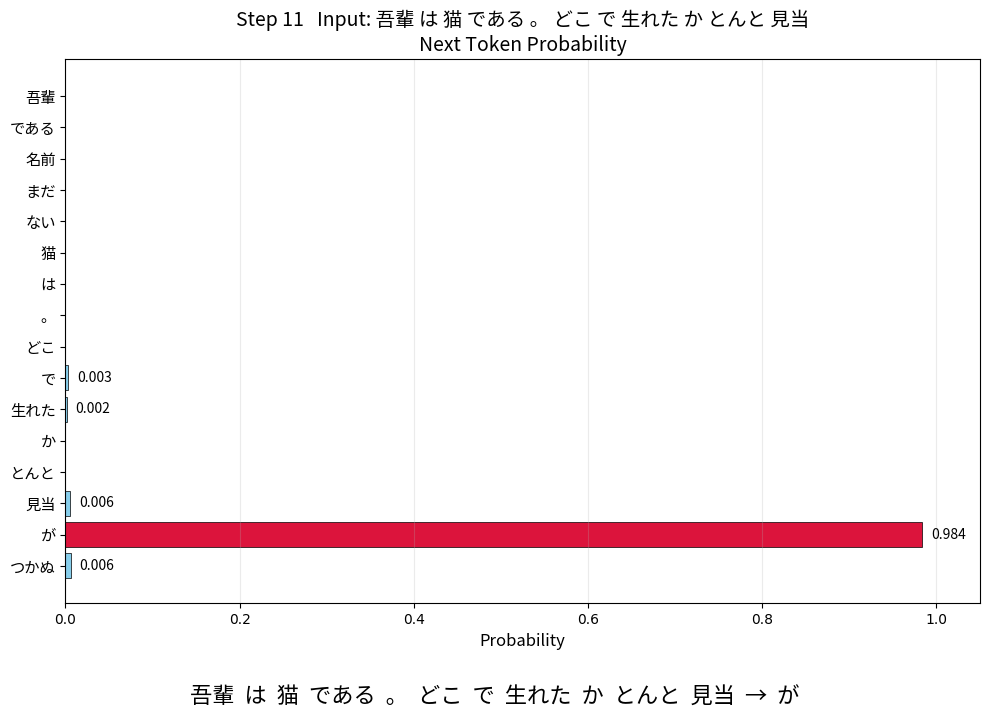


------------------------------------------------------------
Step 12
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が
Prediction : つかぬ
Probability: 0.989277
------------------------------------------------------------


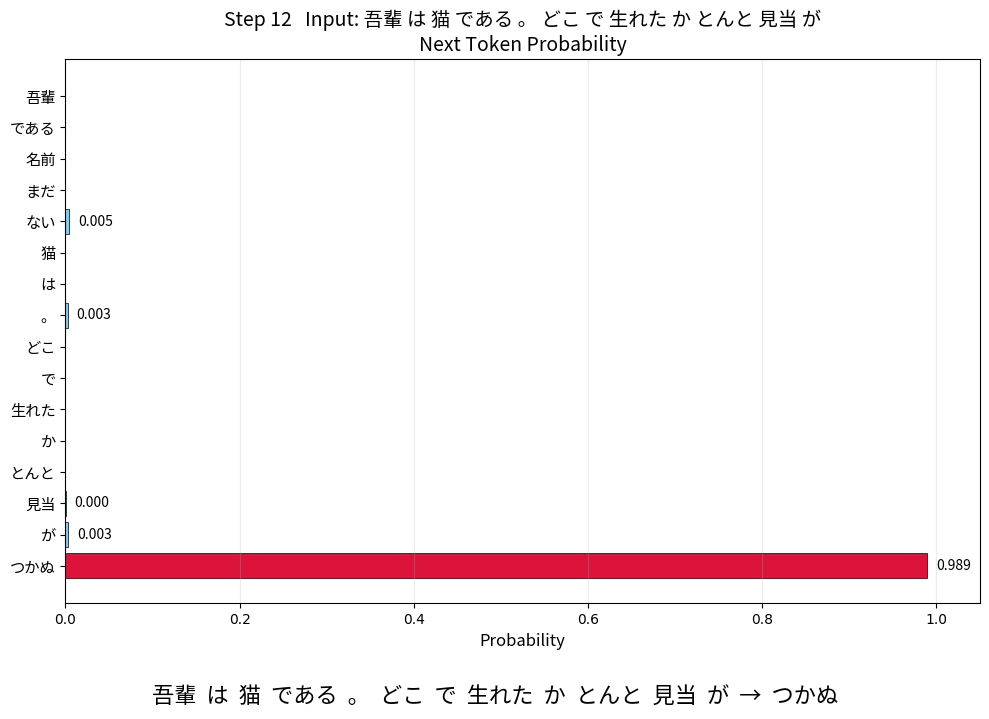


------------------------------------------------------------
Step 13
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ
Prediction : 。
Probability: 0.991422
------------------------------------------------------------


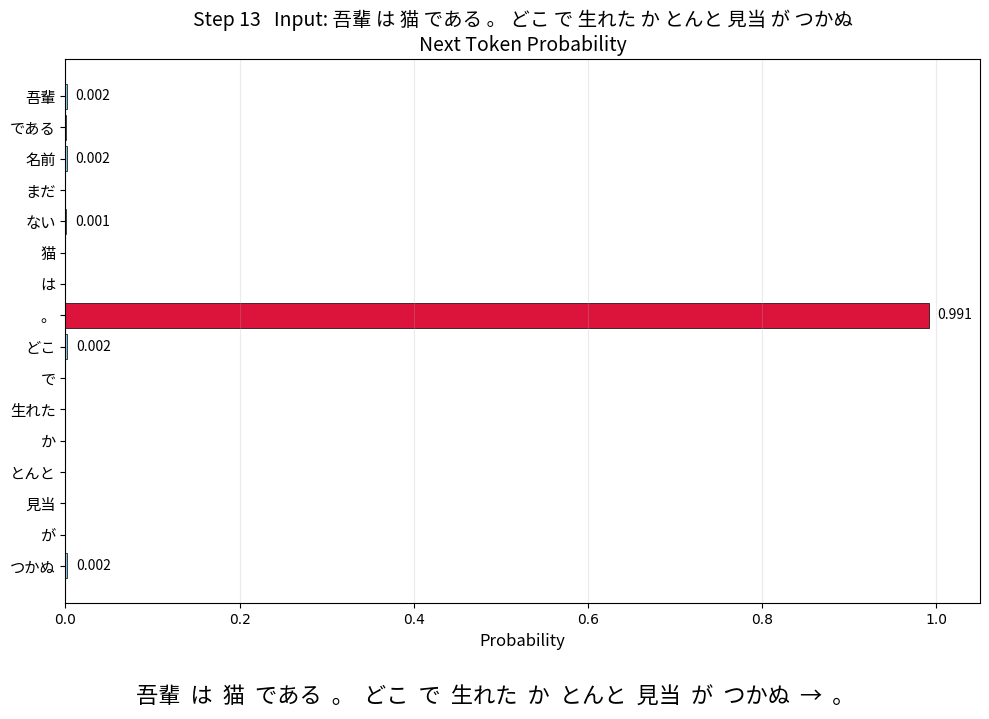


------------------------------------------------------------
Step 14
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。
Prediction : どこ
Probability: 0.333532
------------------------------------------------------------


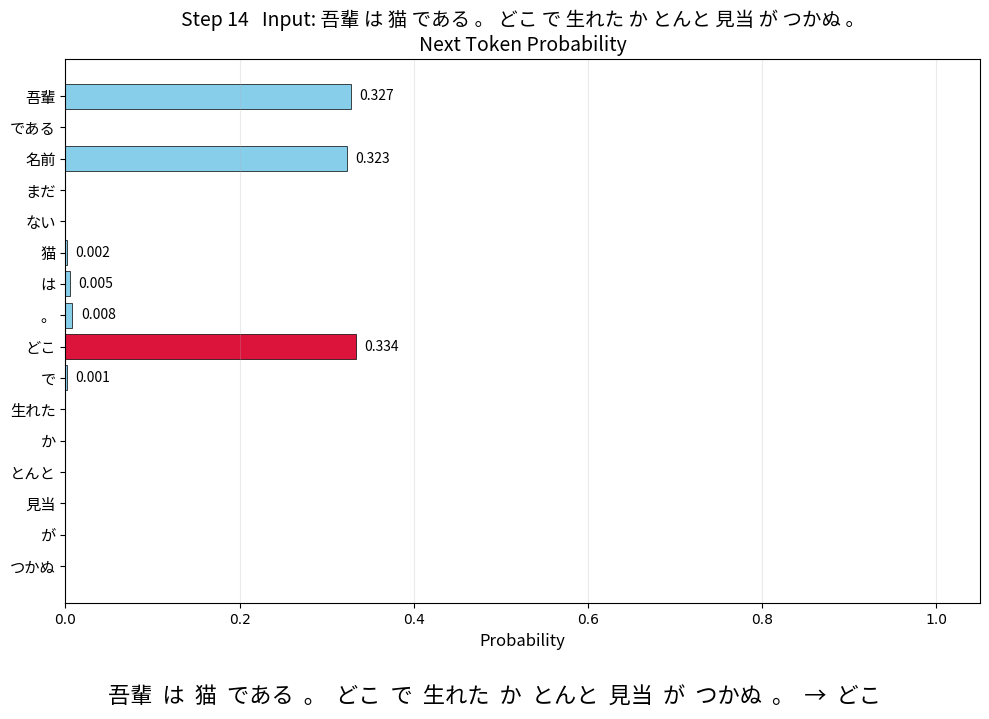


------------------------------------------------------------
Step 15
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ
Prediction : で
Probability: 0.983203
------------------------------------------------------------


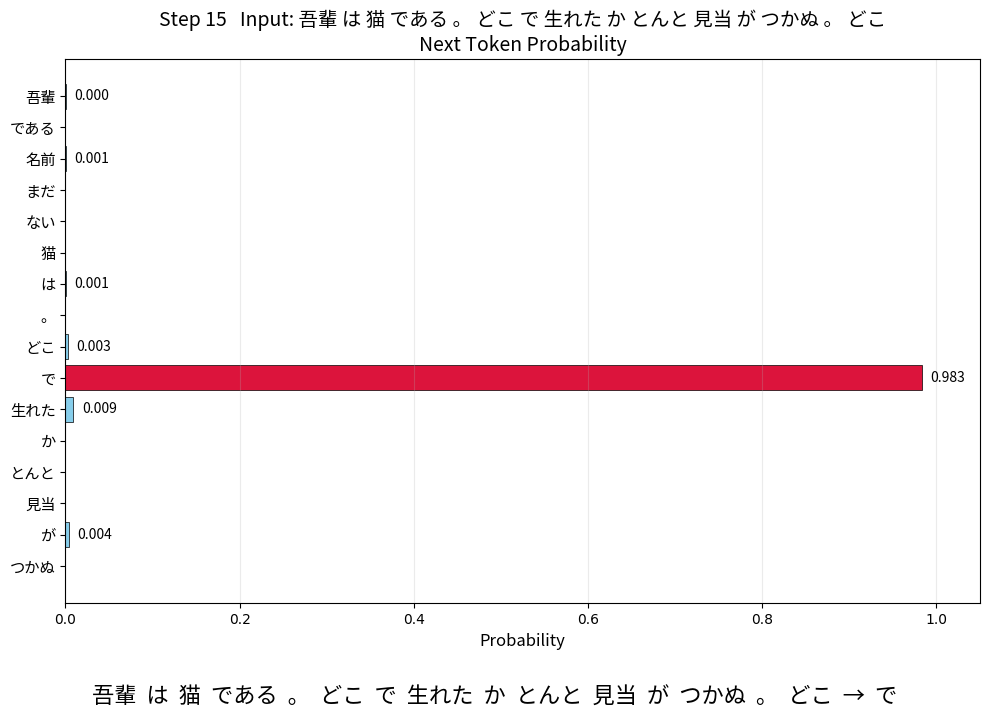


------------------------------------------------------------
Step 16
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ で
Prediction : 生れた
Probability: 0.994666
------------------------------------------------------------


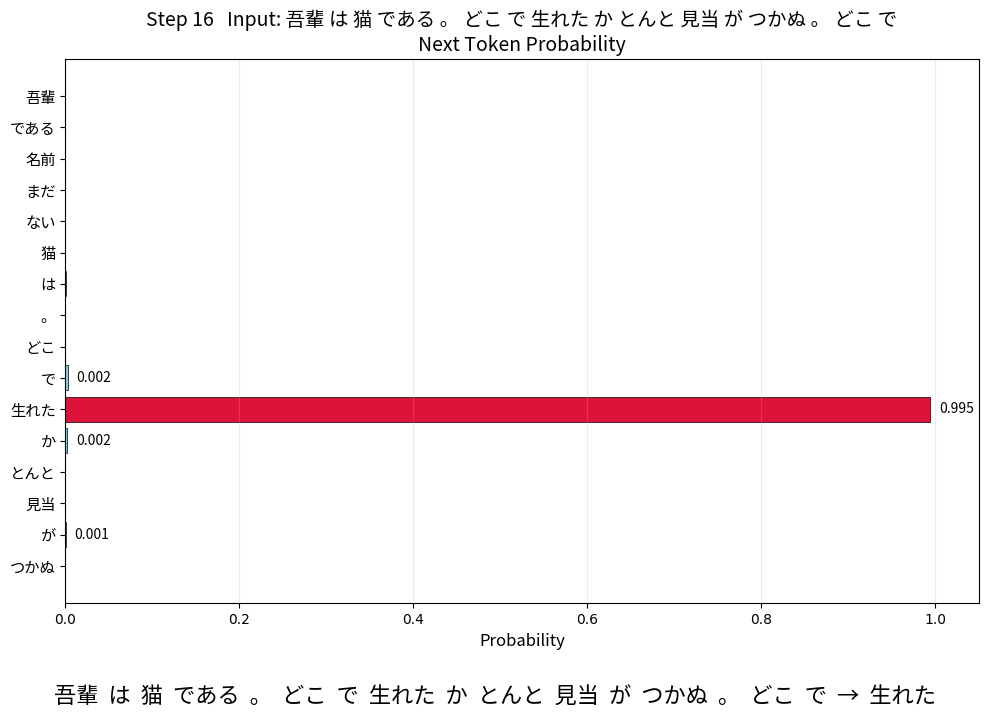


------------------------------------------------------------
Step 17
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ で 生れた
Prediction : か
Probability: 0.986351
------------------------------------------------------------


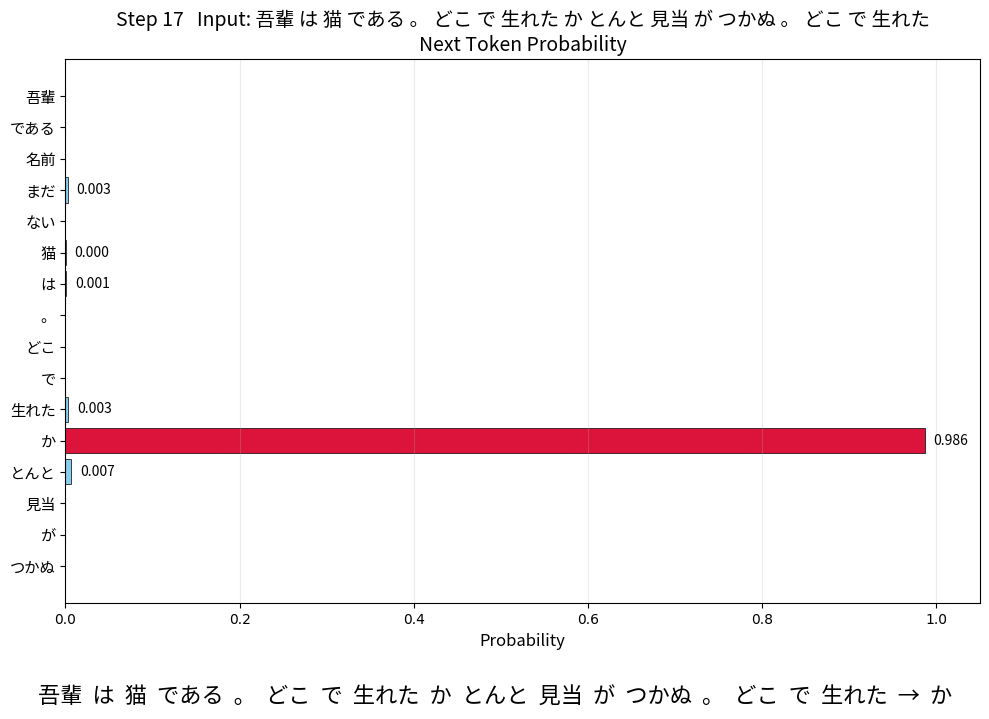


------------------------------------------------------------
Step 18
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ で 生れた か
Prediction : とんと
Probability: 0.992117
------------------------------------------------------------


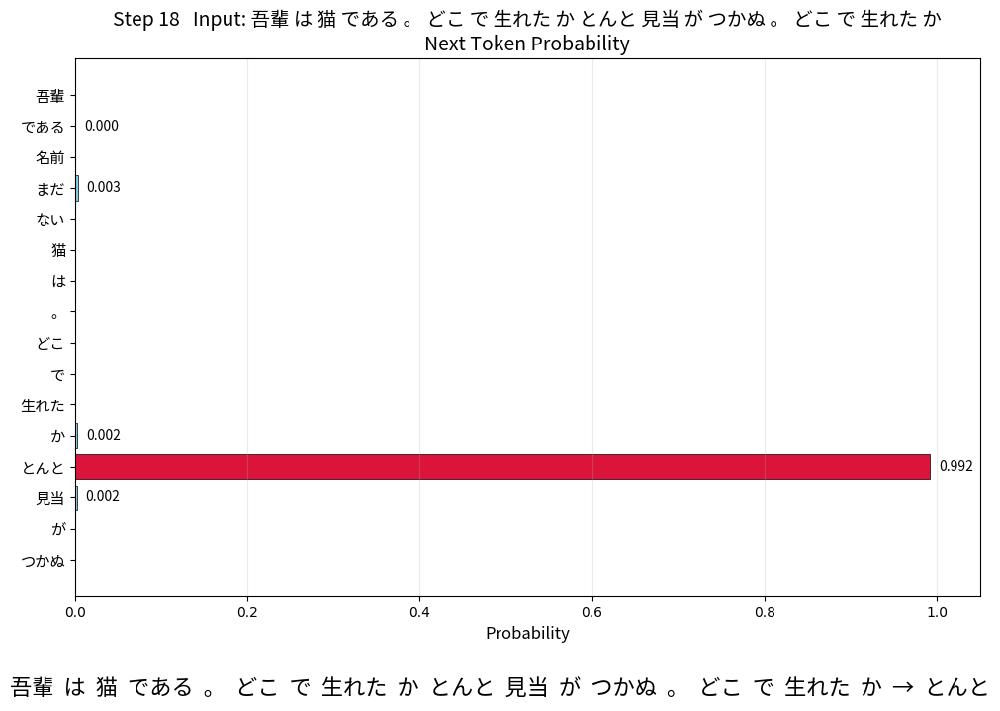


------------------------------------------------------------
Step 19
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ で 生れた か とんと
Prediction : 見当
Probability: 0.988604
------------------------------------------------------------


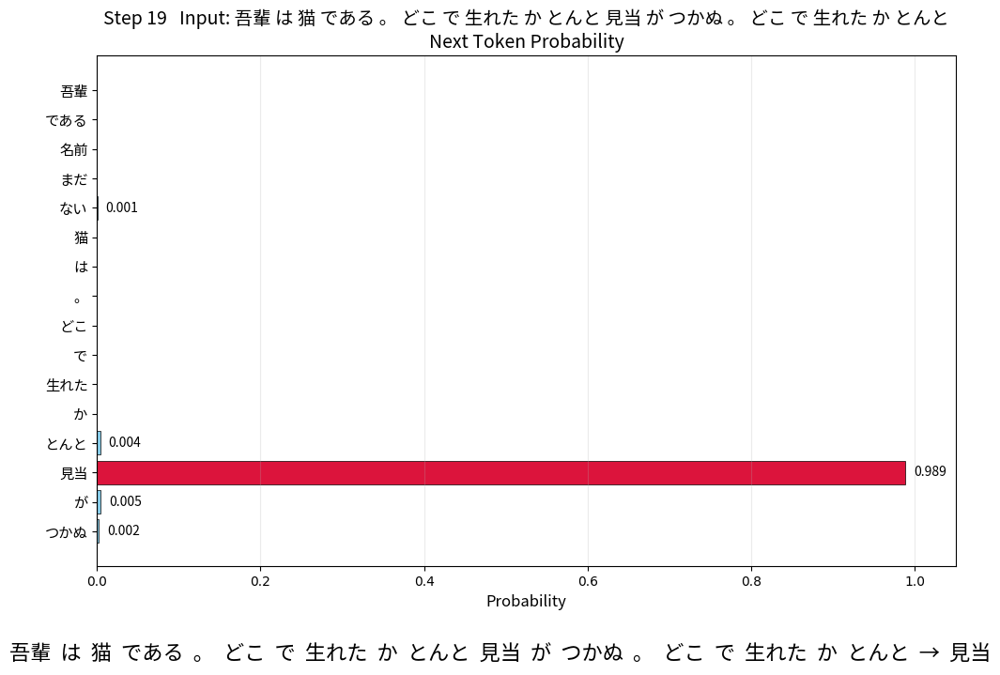


------------------------------------------------------------
Step 20
Input      : 吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ で 生れた か とんと 見当
Prediction : が
Probability: 0.983597
------------------------------------------------------------


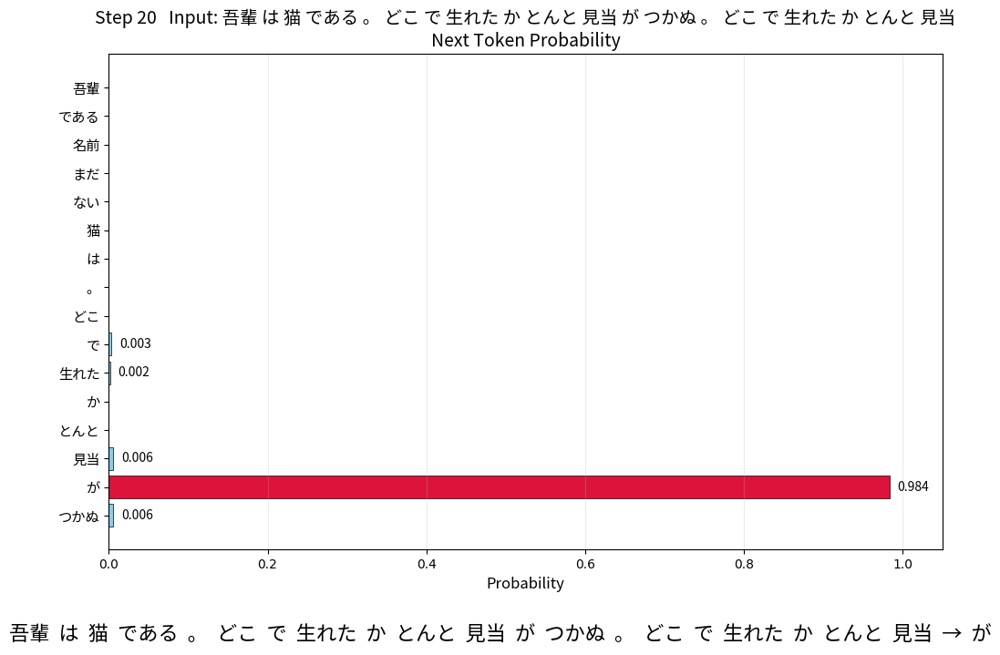


Final sequence:
吾輩 は 猫 である 。 どこ で 生れた か とんと 見当 が つかぬ 。 どこ で 生れた か とんと 見当 が


In [8]:
# @title 【STEP4】　次Token予測確率のグラフを求める。
# ============================================================
# Token-by-Token Next Token Probability
# ============================================================
import os
import pickle
import subprocess
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from model import GPT, GPTConfig

# ============================================================
# Settings
# ============================================================
NANOGPT_DIR = "/content/nanoGPT"
CKPT_PATH = os.path.join(NANOGPT_DIR, "out", "ckpt.pt")
META_PATH = os.path.join(NANOGPT_DIR, "data", "jp", "meta.pkl")
device = "cuda" if torch.cuda.is_available() else "cpu"
NUM_STEPS = 20
START_TOKEN = "吾輩"

# ============================================================
# Japanese font
# ============================================================
def setup_japanese_font():
    candidates = [
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/opentype/noto/NotoSansCJKjp-Regular.otf",
        "/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc",
    ]

    font_path = None
    for path in candidates:
        if os.path.exists(path):
            font_path = path
            break

    if font_path is None:
        print("Japanese font not found. Installing fonts-noto-cjk...")
        subprocess.run(
            ["apt-get", "update", "-qq"],
            check=True
        )
        subprocess.run(
            ["apt-get", "install", "-y", "-qq", "fonts-noto-cjk"],
            check=True
        )
        fm._load_fontmanager(try_read_cache=False)

        for path in candidates:
            if os.path.exists(path):
                font_path = path
                break

    if font_path is None:
        fonts = fm.findSystemFonts()
        for path in fonts:
            if "NotoSansCJK" in path:
                font_path = path
                break

    if font_path is None:
        raise RuntimeError("Japanese font installation failed.")

    jpfont = fm.FontProperties(fname=font_path)
    print("Japanese font =", font_path)
    return jpfont

jpfont = setup_japanese_font()

# ============================================================
# Load vocabulary
# ============================================================
def load_meta_vocabulary(meta_path):
    if not os.path.exists(meta_path):
        raise FileNotFoundError(f"meta.pkl not found: {meta_path}")

    with open(meta_path, "rb") as f:
        meta = pickle.load(f)

    print("meta.pkl keys =", list(meta.keys()))

    if "stoi" in meta and "itos" in meta:
        stoi = meta["stoi"]
        itos_raw = meta["itos"]

        if isinstance(itos_raw, dict):
            max_id = max(int(k) for k in itos_raw.keys())
            itos = []
            for i in range(max_id + 1):
                if i in itos_raw:
                    itos.append(itos_raw[i])
                elif str(i) in itos_raw:
                    itos.append(itos_raw[str(i)])
                else:
                    itos.append(f"<{i}>")
        else:
            itos = list(itos_raw)

        return meta, itos, stoi, itos

    if "vocab" in meta:
        vocab = list(meta["vocab"])
        stoi = {token: i for i, token in enumerate(vocab)}
        return meta, vocab, stoi, vocab

    raise RuntimeError(
        "meta.pkl に stoi/itos または vocab がありません。"
    )

# ============================================================
# Load model
# ============================================================
def load_model(ckpt_path):
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f"checkpoint not found: {ckpt_path}")

    print("Loading checkpoint...")

    checkpoint = torch.load(
        ckpt_path,
        map_location=device,
        weights_only=False
    )

    print("checkpoint keys =", list(checkpoint.keys()))

    if "model_args" not in checkpoint:
        raise RuntimeError("checkpoint に model_args がありません。")

    model_args = checkpoint["model_args"]

    print("Model configuration")
    for k, v in model_args.items():
        print(f"{k:20s}: {v}")

    config = GPTConfig(**model_args)
    model = GPT(config)

    state_dict = checkpoint["model"]

    for k in list(state_dict.keys()):
        if k.startswith("_orig_mod."):
            state_dict[k[len("_orig_mod."):]] = state_dict.pop(k)

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()

    num_params = sum(p.numel() for p in model.parameters())

    print("=" * 60)
    print(f"number of parameters: {num_params:,}")
    print(f"number of parameters: {num_params / 1e3:.2f}K")
    print("=" * 60)

    return model

# ============================================================
# Token utilities
# ============================================================
def token_to_id(token, stoi):
    if token in stoi:
        return int(stoi[token])

    token2 = "▁" + token
    if token2 in stoi:
        return int(stoi[token2])

    raise KeyError(f"Token '{token}' not found.")

def clean_token(token):
    token = str(token)
    token = token.replace("▁", "")
    token = token.replace("\n", "\\n")
    return token if token else "<blank>"

# ============================================================
# Next-token probability
# ============================================================
@torch.no_grad()
def get_next_token_probabilities(model, input_ids):
    x = torch.tensor(
        input_ids,
        dtype=torch.long,
        device=device
    ).unsqueeze(0)

    if x.size(1) > model.config.block_size:
        x = x[:, -model.config.block_size:]

    logits, _ = model(x)
    logits = logits[0, -1, :]

    return torch.softmax(
        logits,
        dim=-1
    ).cpu().numpy()

# ============================================================
# Probability graph
# ============================================================
def plot_probabilities(
    probabilities,
    vocab,
    input_tokens,
    predicted_token,
    step
):
    n = min(len(vocab), len(probabilities))
    probs = probabilities[:n]
    labels = [clean_token(vocab[i]) for i in range(n)]
    predicted_id = int(np.argmax(probs))

    fig, ax = plt.subplots(
        figsize=(10, max(5, 0.45 * n))
    )

    y = np.arange(n)

    colors = [
        "crimson" if i == predicted_id else "skyblue"
        for i in range(n)
    ]

    bars = ax.barh(
        y,
        probs,
        color=colors,
        edgecolor="black",
        linewidth=0.5
    )

    ax.set_yticks(y)
    ax.set_yticklabels(
        labels,
        fontproperties=jpfont,
        fontsize=11
    )

    ax.invert_yaxis()
    ax.set_xlim(0, 1.05)

    ax.set_xlabel(
        "Probability",
        fontproperties=jpfont,
        fontsize=12
    )

    input_text = " ".join(
        clean_token(t)
        for t in input_tokens
    )

    ax.set_title(
        f"Step {step}   Input: {input_text}\n"
        "Next Token Probability",
        fontproperties=jpfont,
        fontsize=14
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    for i, bar in enumerate(bars):
        p = float(probs[i])

        if p >= 0.0001:
            ax.text(
                min(p + 0.01, 1.01),
                bar.get_y() + bar.get_height() / 2,
                f"{p:.3f}",
                va="center",
                fontsize=10,
                fontproperties=jpfont
            )

    sequence_text = (
        "  ".join(
            clean_token(t)
            for t in input_tokens
        )
        + "  →  "
        + clean_token(predicted_token)
    )

    fig.text(
        0.5,
        0.015,
        sequence_text,
        ha="center",
        fontsize=16,
        fontproperties=jpfont
    )

    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.show()
    plt.close(fig)

# ============================================================
# Generation
# ============================================================
def generation_demo():
    print("device     =", device)
    print("checkpoint =", CKPT_PATH)
    print("meta.pkl   =", META_PATH)

    meta, vocab, stoi, itos = load_meta_vocabulary(
        META_PATH
    )

    print("Vocabulary size =", len(vocab))

    model = load_model(CKPT_PATH)

    input_tokens = [START_TOKEN]

    print()
    print("=" * 60)
    print("TOKEN-BY-TOKEN NEXT TOKEN PROBABILITY")
    print("=" * 60)

    for step in range(1, NUM_STEPS + 1):
        input_ids = [
            token_to_id(token, stoi)
            for token in input_tokens
        ]

        probabilities = get_next_token_probabilities(
            model,
            input_ids
        )

        predicted_id = int(np.argmax(probabilities))
        predicted_token = itos[predicted_id]
        predicted_probability = float(
            probabilities[predicted_id]
        )

        print()
        print("-" * 60)
        print(f"Step {step}")
        print(
            "Input      :",
            " ".join(
                clean_token(t)
                for t in input_tokens
            )
        )
        print(
            "Prediction :",
            clean_token(predicted_token)
        )
        print(
            f"Probability: {predicted_probability:.6f}"
        )
        print("-" * 60)

        plot_probabilities(
            probabilities,
            vocab,
            input_tokens,
            predicted_token,
            step
        )

        input_tokens.append(predicted_token)

    print()
    print("=" * 60)
    print("Final sequence:")
    print(
        " ".join(
            clean_token(t)
            for t in input_tokens
        )
    )
    print("=" * 60)

# ============================================================
# Execute
# ============================================================
if __name__ == "__main__":
    generation_demo()

JAPANESE FONT
Font path : /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc
Font name : Noto Sans CJK JP

EMBEDDING HISTORY
History directory : /content/nanoGPT/history
Number of files   : 76
First             : iter_000000.pt
Last              : iter_015000.pt

DATA INFORMATION
Word embedding shape     : (76, 16, 4)
Position embedding shape : (76, 5, 4)
Embedding dimension      : 4
Number of positions      : 5
First iteration          : 0
Last iteration           : 15000


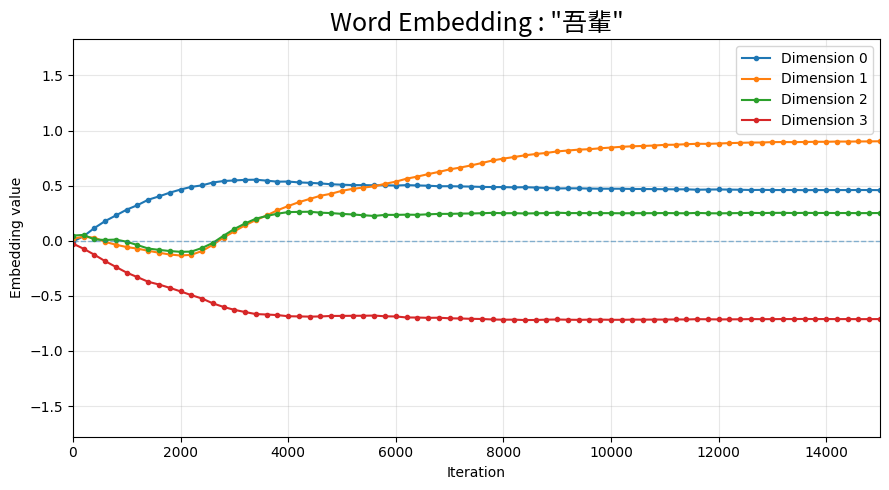

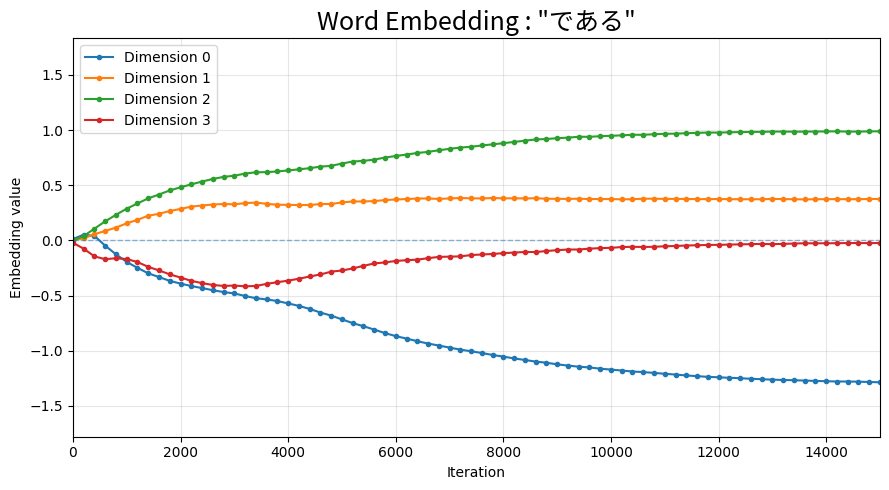

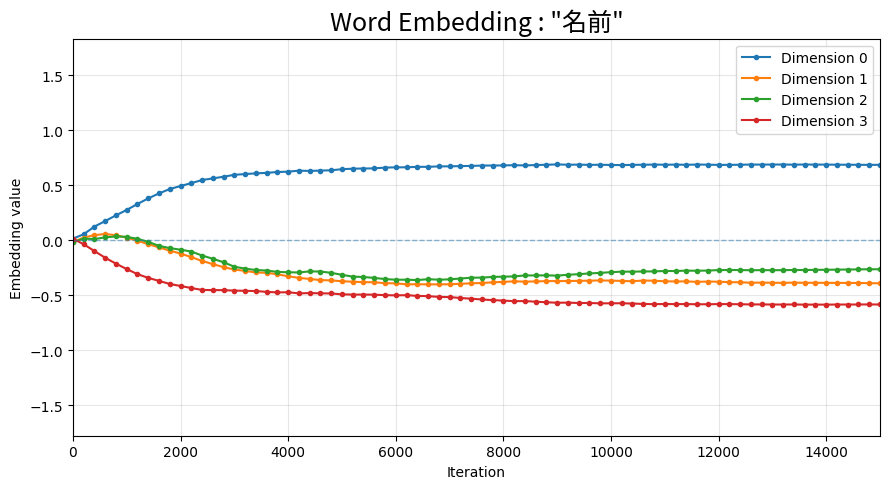

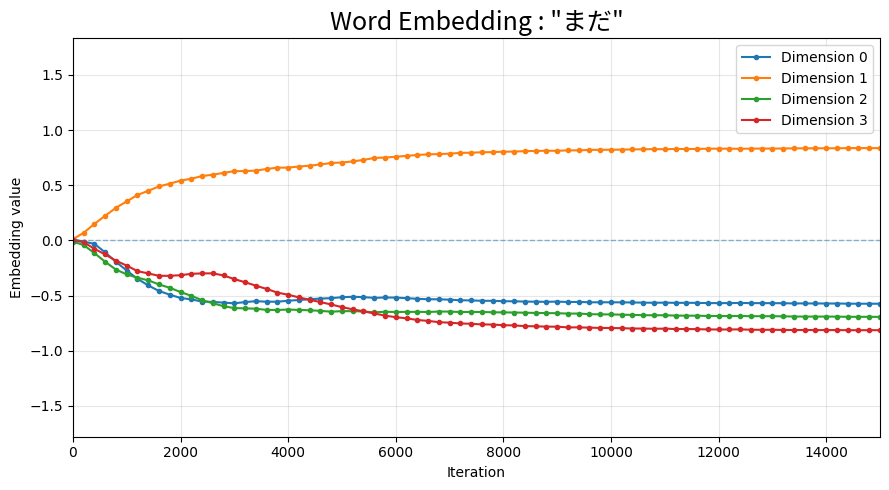

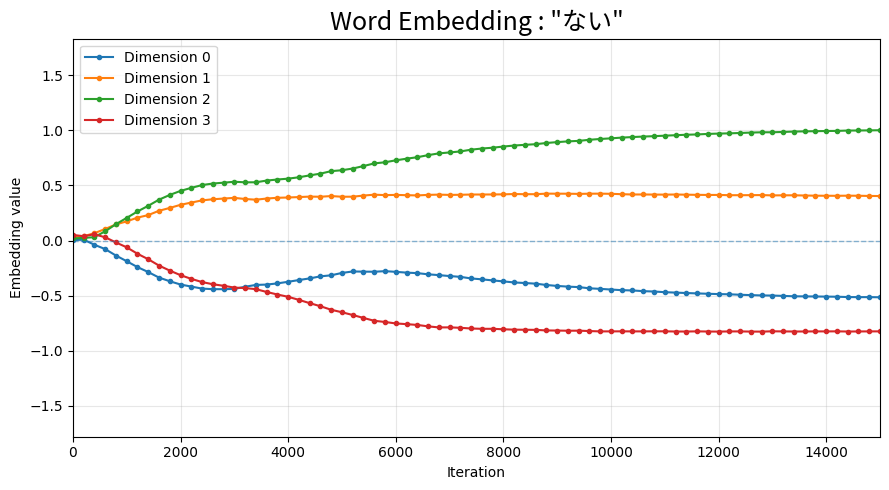

...

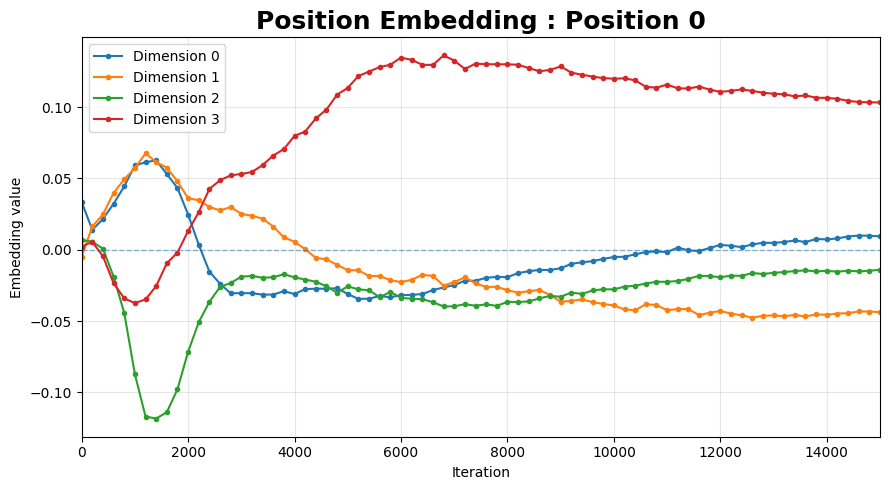

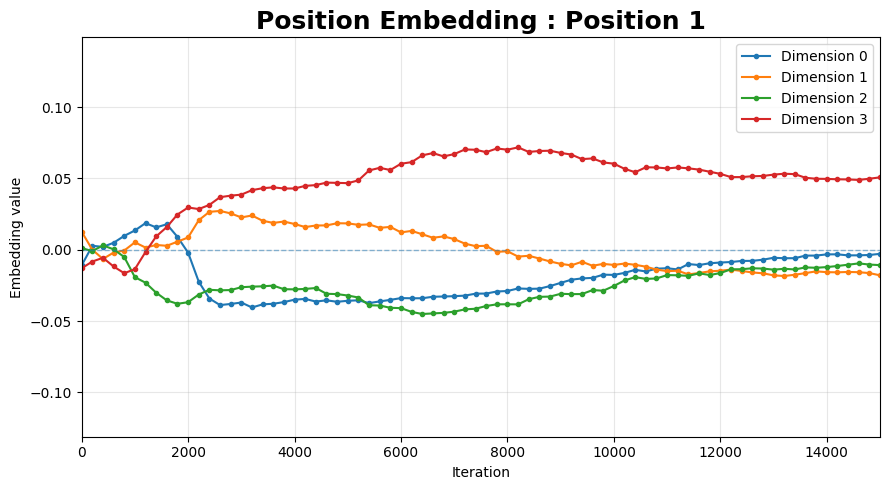

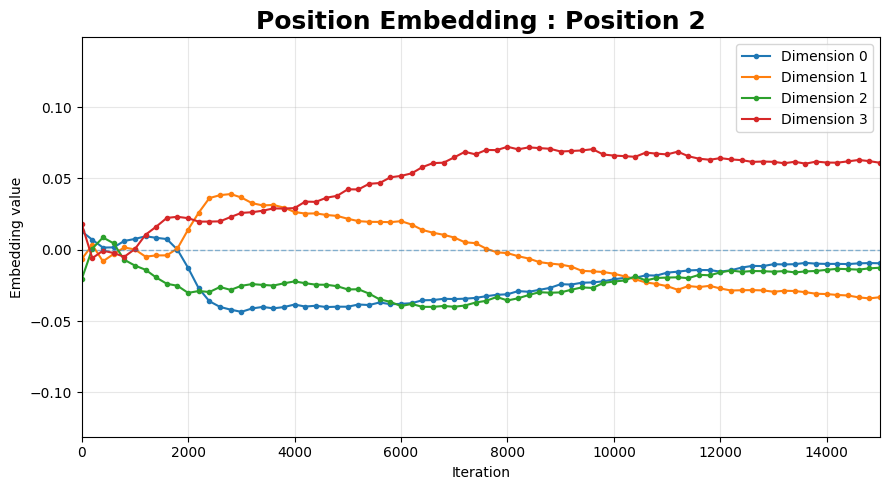

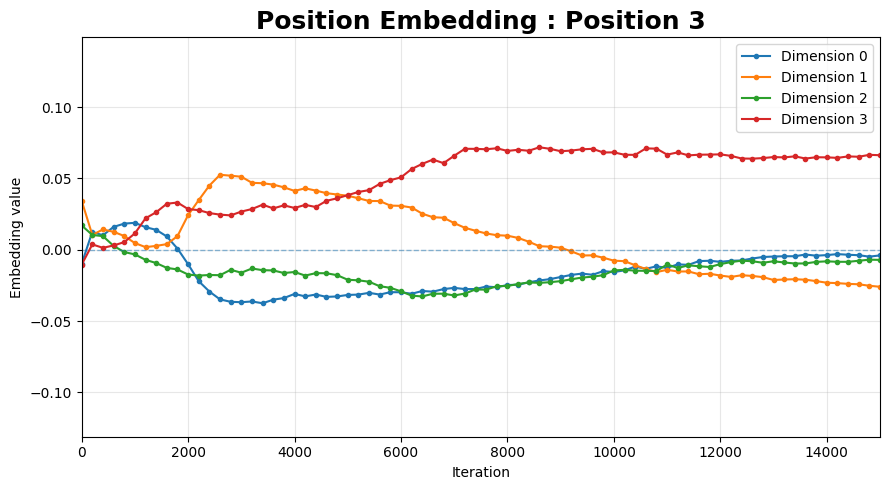

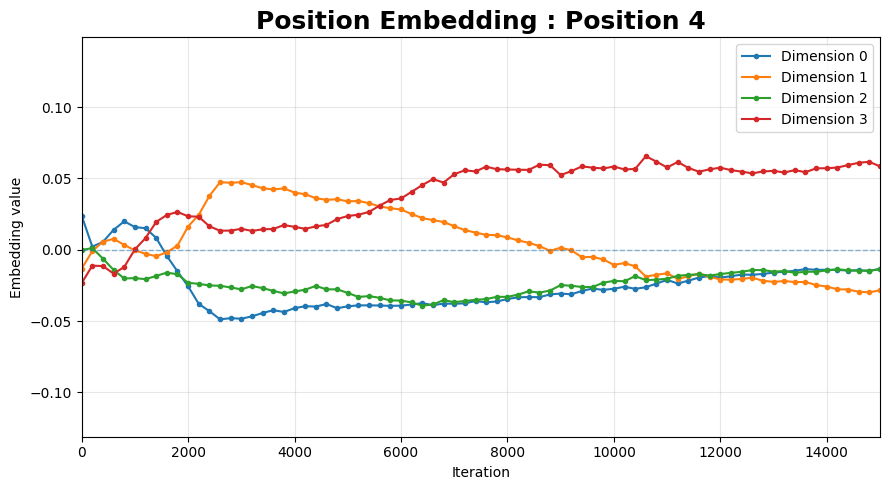

In [ ]:
# @title 【5－1】学習状況の可視化。Word Embedding, Position Embeddingの様子
import os
import glob
import re
import subprocess
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ============================================================
# Settings
# ============================================================
history_dir = "/content/nanoGPT/history"

vocab = [
    "吾輩",
    "である",
    "名前",
    "まだ",
    "ない",
    "猫",
    "は",
    "。",
    "どこ",
    "で",
    "生れた",
    "か",
    "とんと",
    "見当",
    "が",
    "つかぬ"
]

# ============================================================
# Japanese Font
# ============================================================
font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"

if not os.path.exists(font_path):
    print("Japanese font not found.")
    print("Installing fonts-noto-cjk...")
    subprocess.run(
        ["apt-get", "-qq", "update"],
        check=True
    )
    subprocess.run(
        ["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"],
        check=True
    )
    fm._load_fontmanager(try_read_cache=False)

if not os.path.exists(font_path):
    # インストール後、実際のNoto CJKフォントを検索
    candidates = glob.glob(
        "/usr/share/fonts/**/*NotoSansCJK*",
        recursive=True
    )

    if len(candidates) > 0:
        font_path = candidates[0]
    else:
        raise RuntimeError(
            "Japanese font could not be installed."
        )

jpfont = fm.FontProperties(
    fname=font_path
)

print("=" * 60)
print("JAPANESE FONT")
print("=" * 60)
print("Font path :", font_path)
print("Font name :", jpfont.get_name())

# ============================================================
# Load History Files
# ============================================================
files = glob.glob(
    os.path.join(history_dir, "*.pt")
)

if len(files) == 0:
    raise RuntimeError(
        f"No history files found: {history_dir}"
    )

# ============================================================
# Get Iteration Number from Filename
# ============================================================
def get_iteration_from_filename(filename):
    basename = os.path.basename(filename)

    match = re.search(
        r"(\d+)",
        basename
    )

    if match:
        return int(match.group(1))

    return 0

files = sorted(
    files,
    key=get_iteration_from_filename
)

print()
print("=" * 60)
print("EMBEDDING HISTORY")
print("=" * 60)
print("History directory :", history_dir)
print("Number of files   :", len(files))
print("First             :", os.path.basename(files[0]))
print("Last              :", os.path.basename(files[-1]))

# ============================================================
# Read All History
# ============================================================
iterations = []
word_embeddings = []
position_embeddings = []

for history_no, file in enumerate(files):
    h = torch.load(
        file,
        map_location="cpu"
    )

    if "embedding_weight" not in h:
        raise KeyError(
            f"embedding_weight is not found in {file}"
        )

    if "position_weight" not in h:
        raise KeyError(
            f"position_weight is not found in {file}"
        )

    # --------------------------------------------------------
    # Iteration
    # --------------------------------------------------------
    if "iter_num" in h:
        iteration = int(
            h["iter_num"]
        )
    else:
        iteration = get_iteration_from_filename(
            file
        )

        if iteration == 0 and history_no != 0:
            iteration = history_no

    # --------------------------------------------------------
    # Word Embedding
    # --------------------------------------------------------
    word_emb = h[
        "embedding_weight"
    ]

    if torch.is_tensor(word_emb):
        word_emb = (
            word_emb
            .detach()
            .cpu()
            .float()
            .numpy()
        )

    # --------------------------------------------------------
    # Position Embedding
    # --------------------------------------------------------
    pos_emb = h[
        "position_weight"
    ]

    if torch.is_tensor(pos_emb):
        pos_emb = (
            pos_emb
            .detach()
            .cpu()
            .float()
            .numpy()
        )

    iterations.append(
        iteration
    )

    word_embeddings.append(
        word_emb
    )

    position_embeddings.append(
        pos_emb
    )

# ============================================================
# Convert to NumPy
# ============================================================
iterations = np.array(
    iterations,
    dtype=int
)

word_embeddings = np.array(
    word_embeddings
)

position_embeddings = np.array(
    position_embeddings
)

# ============================================================
# Sort by Iteration
# ============================================================
order = np.argsort(
    iterations
)

iterations = iterations[
    order
]

word_embeddings = word_embeddings[
    order
]

position_embeddings = position_embeddings[
    order
]

# ============================================================
# Check Shape
# ============================================================
if word_embeddings.ndim != 3:
    raise RuntimeError(
        "word_embeddings must have shape "
        "[history, vocab, dimension]"
    )

if position_embeddings.ndim != 3:
    raise RuntimeError(
        "position_embeddings must have shape "
        "[history, position, dimension]"
    )

if len(vocab) > word_embeddings.shape[1]:
    raise RuntimeError(
        f"vocab contains {len(vocab)} tokens, "
        f"but embedding table contains only "
        f"{word_embeddings.shape[1]} tokens."
    )

print()
print("=" * 60)
print("DATA INFORMATION")
print("=" * 60)
print(
    "Word embedding shape     :",
    word_embeddings.shape
)
print(
    "Position embedding shape :",
    position_embeddings.shape
)
print(
    "Embedding dimension      :",
    word_embeddings.shape[2]
)
print(
    "Number of positions      :",
    position_embeddings.shape[1]
)
print(
    "First iteration          :",
    iterations[0]
)
print(
    "Last iteration           :",
    iterations[-1]
)

# ============================================================
# Common Y Range for Word Embedding
# ============================================================
word_ymin = float(
    np.min(word_embeddings)
)

word_ymax = float(
    np.max(word_embeddings)
)

word_margin = (
    word_ymax - word_ymin
) * 0.05

if word_margin == 0:
    word_margin = 0.1

word_ymin -= word_margin
word_ymax += word_margin

# ============================================================
# WORD EMBEDDING
# ============================================================
for word_id, word in enumerate(vocab):
    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    for dim in range(
        word_embeddings.shape[2]
    ):
        values = word_embeddings[
            :,
            word_id,
            dim
        ]

        ax.plot(
            iterations,
            values,
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=f"Dimension {dim}"
        )

    ax.axhline(
        0,
        linewidth=1,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(
        f'Word Embedding : "{word}"',
        fontproperties=jpfont,
        fontsize=18
    )

    ax.set_xlabel(
        "Iteration"
    )

    ax.set_ylabel(
        "Embedding value"
    )

    ax.set_ylim(
        word_ymin,
        word_ymax
    )

    if iterations.min() != iterations.max():
        ax.set_xlim(
            iterations.min(),
            iterations.max()
        )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)

# ============================================================
# Common Y Range for Position Embedding
# ============================================================
pos_ymin = float(
    np.min(position_embeddings)
)

pos_ymax = float(
    np.max(position_embeddings)
)

pos_margin = (
    pos_ymax - pos_ymin
) * 0.05

if pos_margin == 0:
    pos_margin = 0.1

pos_ymin -= pos_margin
pos_ymax += pos_margin

# ============================================================
# POSITION EMBEDDING
# ============================================================
for position in range(
    position_embeddings.shape[1]
):
    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    for dim in range(
        position_embeddings.shape[2]
    ):
        values = position_embeddings[
            :,
            position,
            dim
        ]

        ax.plot(
            iterations,
            values,
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=f"Dimension {dim}"
        )

    ax.axhline(
        0,
        linewidth=1,
        linestyle="--",
        alpha=0.5
    )

    ax.set_title(
        f"Position Embedding : Position {position}",
        fontsize=18,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Iteration"
    )

    ax.set_ylabel(
        "Embedding value"
    )

    ax.set_ylim(
        pos_ymin,
        pos_ymax
    )

    if iterations.min() != iterations.max():
        ax.set_xlim(
            iterations.min(),
            iterations.max()
        )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)

TOKEN / POSITION EMBEDDING PCA TRAJECTORIES
History directory : /content/nanoGPT/history
Number of files   : 76
Display interval  : 600
Word vectors shape     : (1216, 4)
Position vectors shape : (380, 4)
Embedding dimension    : 4
TOKEN EMBEDDING PCA
PC1       = 38.12%
PC2       = 33.62%
PC1 + PC2 = 71.74%
POSITION EMBEDDING PCA
PC1       = 65.18%
PC2       = 22.71%
PC1 + PC2 = 87.89%
TRAJECTORY
First iteration : 0
Last iteration  : 15000
Points          : 26


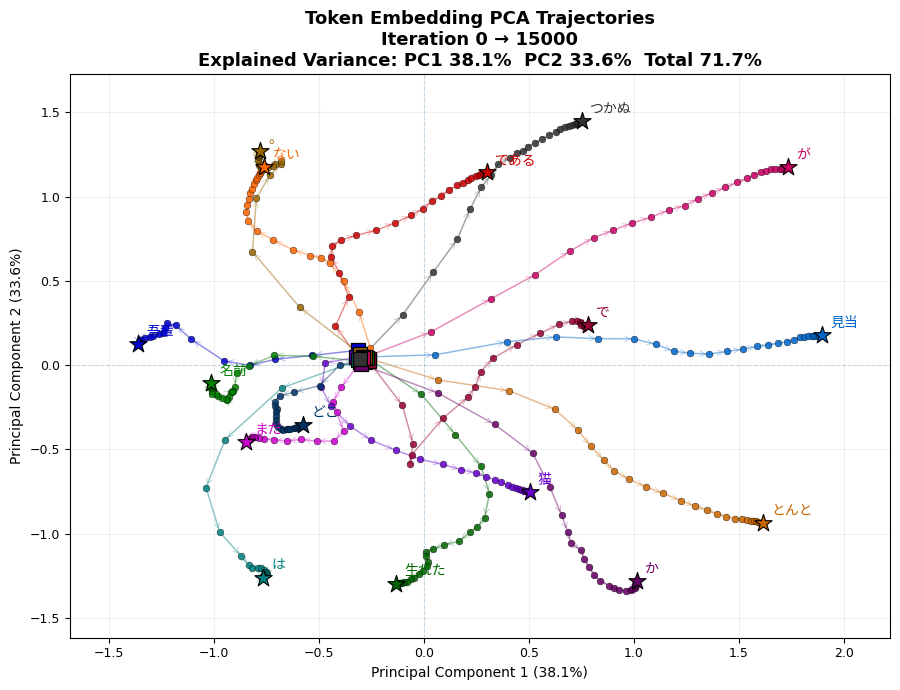

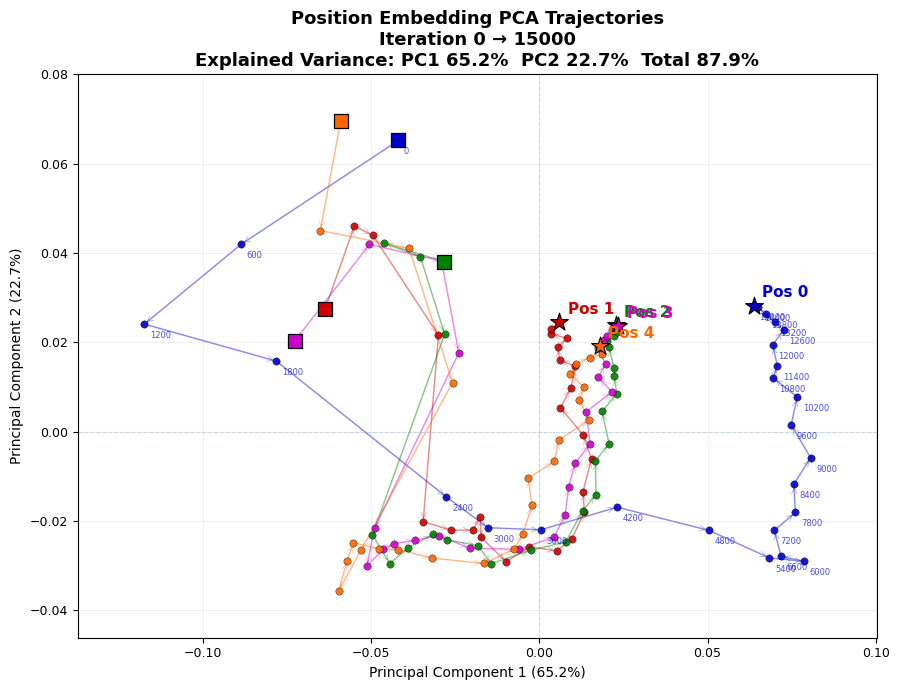

In [10]:
# @title 【STEP5－2】主成分分析（PCA)によるWord　EmbeddingとPosition Embeddingの可視化（４次元ベクトルを３次元ベクトルで近似）
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.decomposition import PCA

# ============================================================
# Settings
# ============================================================
history_dir = "/content/nanoGPT/history"
display_interval = 600
line_alpha = 0.28
figsize = (9.1, 7.0)
vocab = [
    "吾輩", "である", "名前", "まだ", "ない", "猫", "は", "。",
    "どこ", "で", "生れた", "か", "とんと", "見当", "が", "つかぬ"
]

# ============================================================
# Japanese Font
# ============================================================
font_candidates = [
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
    "/usr/share/fonts/opentype/noto/NotoSansCJKjp-Regular.otf"
]
jpfont = None
for path in font_candidates:
    if os.path.exists(path):
        jpfont = font_manager.FontProperties(fname=path)
        break
if jpfont is None:
    print("WARNING: Japanese font was not found.")

# ============================================================
# Colors
# ============================================================
token_colors = [
    "#0000CC", "#CC0000", "#008000", "#CC00CC",
    "#FF6600", "#6600CC", "#008080", "#996600",
    "#003366", "#990033", "#006600", "#660066",
    "#CC6600", "#0066CC", "#CC0066", "#333333"
]
position_colors = [
    "#0000CC", "#CC0000", "#008000", "#CC00CC",
    "#FF6600", "#6600CC", "#008080", "#996600",
    "#003366", "#990033"
]

# ============================================================
# Load History Files
# ============================================================
files = sorted(glob.glob(os.path.join(history_dir, "*.pt")))
if len(files) == 0:
    raise RuntimeError(f"No history files found: {history_dir}")
print("=" * 60)
print("TOKEN / POSITION EMBEDDING PCA TRAJECTORIES")
print("=" * 60)
print("History directory :", history_dir)
print("Number of files   :", len(files))
print("Display interval  :", display_interval)

# ============================================================
# Load All Histories
# ============================================================
histories = []
for history_no, file in enumerate(files):
    h = torch.load(file, map_location="cpu")
    if "embedding_weight" not in h:
        raise KeyError(f"embedding_weight is not found in {file}")
    if "position_weight" not in h:
        raise KeyError(f"position_weight is not found in {file}")
    if "iter_num" in h:
        iteration = int(h["iter_num"])
    else:
        basename = os.path.basename(file)
        try:
            iteration = int(basename.replace("iter_", "").replace(".pt", ""))
        except:
            iteration = history_no
    word = h["embedding_weight"]
    position = h["position_weight"]
    if torch.is_tensor(word):
        word = word.detach().cpu().float().numpy()
    if torch.is_tensor(position):
        position = position.detach().cpu().float().numpy()
    if word.shape[0] != len(vocab):
        raise ValueError(f"vocab={len(vocab)}, embedding_weight={word.shape[0]}")
    histories.append((iteration, word, position))

# ============================================================
# Sort Histories
# ============================================================
histories = sorted(histories, key=lambda x: x[0])
all_word_vectors = np.vstack([word for _, word, _ in histories])
all_position_vectors = np.vstack([position for _, _, position in histories])
print("Word vectors shape     :", all_word_vectors.shape)
print("Position vectors shape :", all_position_vectors.shape)
print("Embedding dimension    :", all_word_vectors.shape[1])

# ============================================================
# TOKEN EMBEDDING PCA
# ============================================================
word_pca = PCA(n_components=2)
word_pca.fit(all_word_vectors)
word_pc1 = word_pca.explained_variance_ratio_[0] * 100
word_pc2 = word_pca.explained_variance_ratio_[1] * 100
word_total = word_pc1 + word_pc2
print("=" * 60)
print("TOKEN EMBEDDING PCA")
print("=" * 60)
print(f"PC1       = {word_pc1:.2f}%")
print(f"PC2       = {word_pc2:.2f}%")
print(f"PC1 + PC2 = {word_total:.2f}%")

# ============================================================
# POSITION EMBEDDING PCA
# ============================================================
position_pca = PCA(n_components=2)
position_pca.fit(all_position_vectors)
position_pc1 = position_pca.explained_variance_ratio_[0] * 100
position_pc2 = position_pca.explained_variance_ratio_[1] * 100
position_total = position_pc1 + position_pc2
print("=" * 60)
print("POSITION EMBEDDING PCA")
print("=" * 60)
print(f"PC1       = {position_pc1:.2f}%")
print(f"PC2       = {position_pc2:.2f}%")
print(f"PC1 + PC2 = {position_total:.2f}%")

# ============================================================
# Transform All Histories
# ============================================================
results = []
for iteration, word, position in histories:
    word_xy = word_pca.transform(word)
    position_xy = position_pca.transform(position)
    results.append((iteration, word_xy, position_xy))

# ============================================================
# Select Every 600 Iterations
# ============================================================
selected_results = [
    (iteration, word_xy, position_xy)
    for iteration, word_xy, position_xy in results
    if iteration % display_interval == 0
]
if len(selected_results) == 0:
    raise RuntimeError("No history found at selected intervals.")
iterations = np.array([iteration for iteration, _, _ in selected_results])
word_history = np.stack([word_xy for _, word_xy, _ in selected_results])
position_history = np.stack([position_xy for _, _, position_xy in selected_results])
print("=" * 60)
print("TRAJECTORY")
print("=" * 60)
print("First iteration :", iterations[0])
print("Last iteration  :", iterations[-1])
print("Points          :", len(iterations))

# ============================================================
# TOKEN EMBEDDING AXIS
# ============================================================
word_xmin = word_history[:, :, 0].min()
word_xmax = word_history[:, :, 0].max()
word_ymin = word_history[:, :, 1].min()
word_ymax = word_history[:, :, 1].max()
word_xmargin = (word_xmax - word_xmin) * 0.10
word_ymargin = (word_ymax - word_ymin) * 0.10
if word_xmargin == 0:
    word_xmargin = 0.01
if word_ymargin == 0:
    word_ymargin = 0.01
word_xmin -= word_xmargin
word_xmax += word_xmargin
word_ymin -= word_ymargin
word_ymax += word_ymargin

# ============================================================
# TOKEN EMBEDDING TRAJECTORIES
# ============================================================
fig, ax = plt.subplots(figsize=figsize)
for i, token in enumerate(vocab):
    color = token_colors[i]
    x = word_history[:, i, 0]
    y = word_history[:, i, 1]

    # Thin trajectory
    ax.plot(
        x, y,
        linewidth=1.2,
        color=color,
        alpha=line_alpha,
        zorder=1
    )

    # Every 600 iterations
    ax.scatter(
        x, y,
        s=24,
        marker="o",
        color=color,
        edgecolors="black",
        linewidths=0.3,
        alpha=0.85,
        zorder=2
    )

    # Direction arrows
    for k in range(len(x) - 1):
        ax.annotate(
            "",
            xy=(x[k + 1], y[k + 1]),
            xytext=(x[k], y[k]),
            arrowprops=dict(
                arrowstyle="->",
                color=color,
                lw=0.7,
                alpha=line_alpha
            ),
            zorder=1
        )

    # Start
    ax.scatter(
        x[0], y[0],
        s=100,
        marker="s",
        color=color,
        edgecolors="black",
        linewidths=0.9,
        zorder=4
    )

    # End
    ax.scatter(
        x[-1], y[-1],
        s=170,
        marker="*",
        color=color,
        edgecolors="black",
        linewidths=0.8,
        zorder=5
    )

    # Token label at final point
    ax.annotate(
        token,
        (x[-1], y[-1]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10,
        fontproperties=jpfont,
        color=color,
        zorder=6
    )

ax.axhline(0, linestyle="--", linewidth=0.8, alpha=0.20)
ax.axvline(0, linestyle="--", linewidth=0.8, alpha=0.20)
ax.set_xlim(word_xmin, word_xmax)
ax.set_ylim(word_ymin, word_ymax)
ax.set_title(
    f"Token Embedding PCA Trajectories\n"
    f"Iteration {iterations[0]} → {iterations[-1]}\n"
    f"Explained Variance: PC1 {word_pc1:.1f}%  "
    f"PC2 {word_pc2:.1f}%  Total {word_total:.1f}%",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel(f"Principal Component 1 ({word_pc1:.1f}%)", fontsize=10)
ax.set_ylabel(f"Principal Component 2 ({word_pc2:.1f}%)", fontsize=10)
ax.tick_params(axis="both", labelsize=9)
ax.grid(True, alpha=0.18)
plt.tight_layout()
plt.show()
plt.close(fig)

# ============================================================
# POSITION EMBEDDING AXIS
# ============================================================
position_xmin = position_history[:, :, 0].min()
position_xmax = position_history[:, :, 0].max()
position_ymin = position_history[:, :, 1].min()
position_ymax = position_history[:, :, 1].max()
position_xmargin = (position_xmax - position_xmin) * 0.10
position_ymargin = (position_ymax - position_ymin) * 0.10
if position_xmargin == 0:
    position_xmargin = 0.01
if position_ymargin == 0:
    position_ymargin = 0.01
position_xmin -= position_xmargin
position_xmax += position_xmargin
position_ymin -= position_ymargin
position_ymax += position_ymargin

# ============================================================
# POSITION EMBEDDING TRAJECTORIES
# ============================================================
fig, ax = plt.subplots(figsize=figsize)
n_positions = position_history.shape[1]
for p in range(n_positions):
    color = position_colors[p % len(position_colors)]
    x = position_history[:, p, 0]
    y = position_history[:, p, 1]

    # Thin trajectory
    ax.plot(
        x, y,
        linewidth=1.2,
        color=color,
        alpha=line_alpha,
        zorder=1
    )

    # Every 600 iterations
    ax.scatter(
        x, y,
        s=28,
        marker="o",
        color=color,
        edgecolors="black",
        linewidths=0.3,
        alpha=0.90,
        zorder=2
    )

    # Direction arrows
    for k in range(len(x) - 1):
        ax.annotate(
            "",
            xy=(x[k + 1], y[k + 1]),
            xytext=(x[k], y[k]),
            arrowprops=dict(
                arrowstyle="->",
                color=color,
                lw=0.7,
                alpha=line_alpha
            ),
            zorder=1
        )

    # Start
    ax.scatter(
        x[0], y[0],
        s=110,
        marker="s",
        color=color,
        edgecolors="black",
        linewidths=0.9,
        zorder=4
    )

    # End
    ax.scatter(
        x[-1], y[-1],
        s=180,
        marker="*",
        color=color,
        edgecolors="black",
        linewidths=0.8,
        zorder=5
    )

    # Position label at final point
    ax.annotate(
        f"Pos {p}",
        (x[-1], y[-1]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color=color,
        zorder=6
    )

# ============================================================
# Iteration Labels for Pos 0
# ============================================================
x0 = position_history[:, 0, 0]
y0 = position_history[:, 0, 1]
for k, iteration in enumerate(iterations):
    ax.annotate(
        str(iteration),
        (x0[k], y0[k]),
        xytext=(4, -10),
        textcoords="offset points",
        fontsize=6,
        color=position_colors[0],
        alpha=0.70
    )

# ============================================================
# Position Plot
# ============================================================
if position_ymin <= 0 <= position_ymax:
    ax.axhline(0, linestyle="--", linewidth=0.8, alpha=0.20)
if position_xmin <= 0 <= position_xmax:
    ax.axvline(0, linestyle="--", linewidth=0.8, alpha=0.20)
ax.set_xlim(position_xmin, position_xmax)
ax.set_ylim(position_ymin, position_ymax)
ax.set_title(
    f"Position Embedding PCA Trajectories\n"
    f"Iteration {iterations[0]} → {iterations[-1]}\n"
    f"Explained Variance: PC1 {position_pc1:.1f}%  "
    f"PC2 {position_pc2:.1f}%  Total {position_total:.1f}%",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel(f"Principal Component 1 ({position_pc1:.1f}%)", fontsize=10)
ax.set_ylabel(f"Principal Component 2 ({position_pc2:.1f}%)", fontsize=10)
ax.tick_params(axis="both", labelsize=9)
ax.grid(True, alpha=0.18)
plt.tight_layout()
plt.show()
plt.close(fig)

WQ / WK / WV HISTORY HEATMAP
History directory : /content/nanoGPT/history
Number of files   : 76
First             : iter_000000.pt
Last              : iter_015000.pt
Common color range : -1.0512 ～ 1.0512


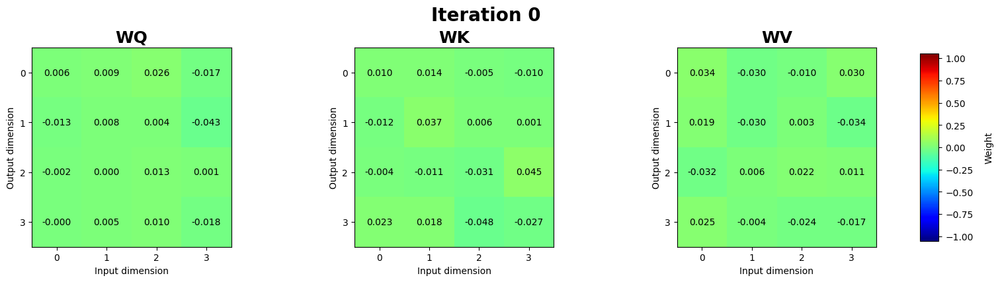

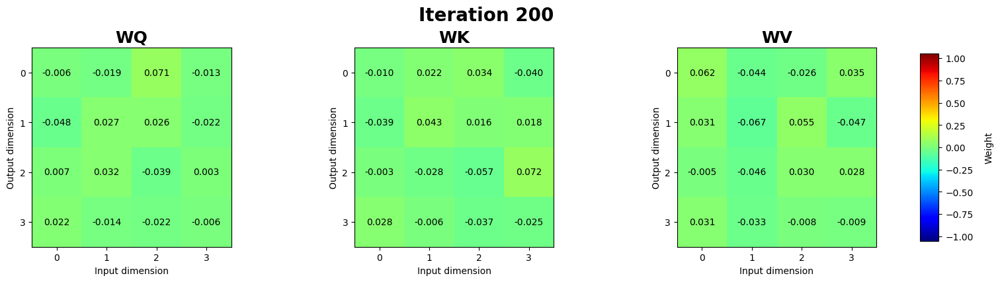

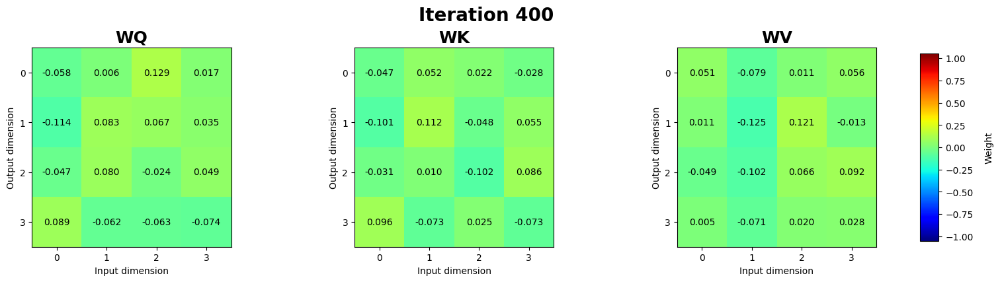

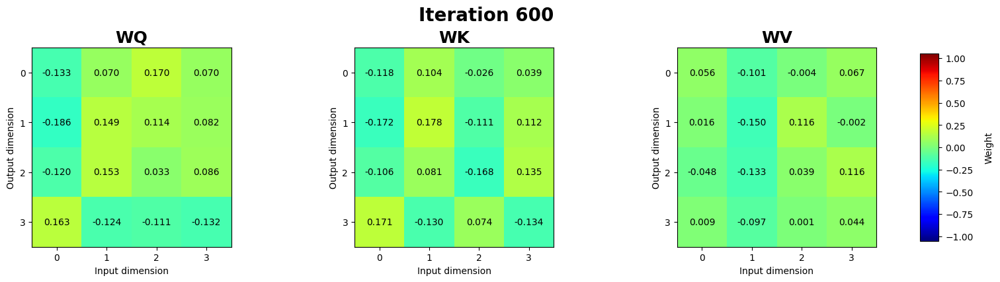

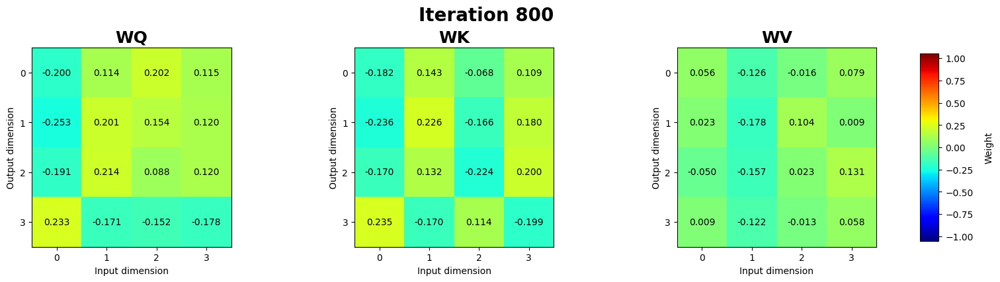

...

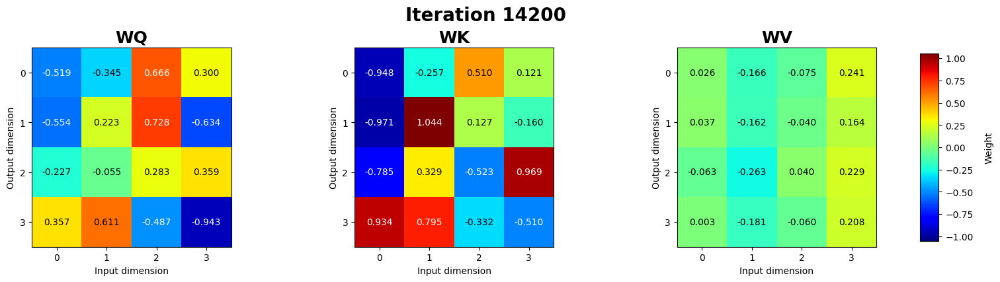

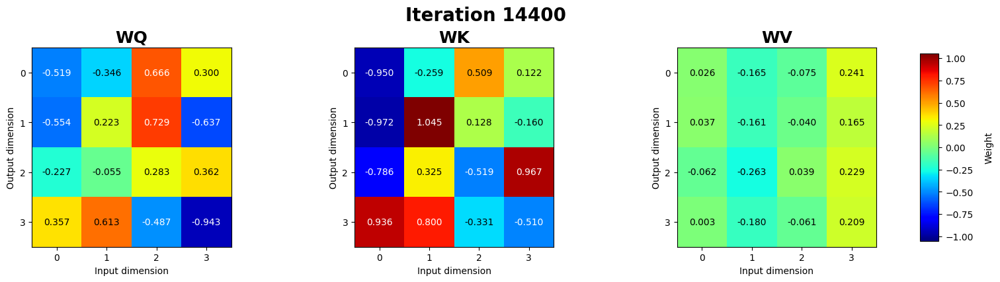

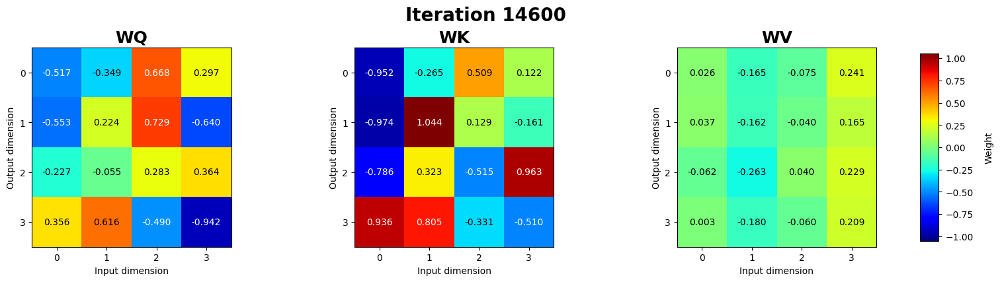

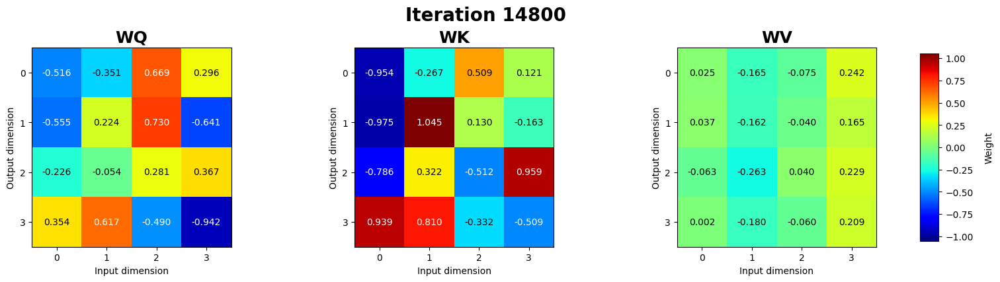

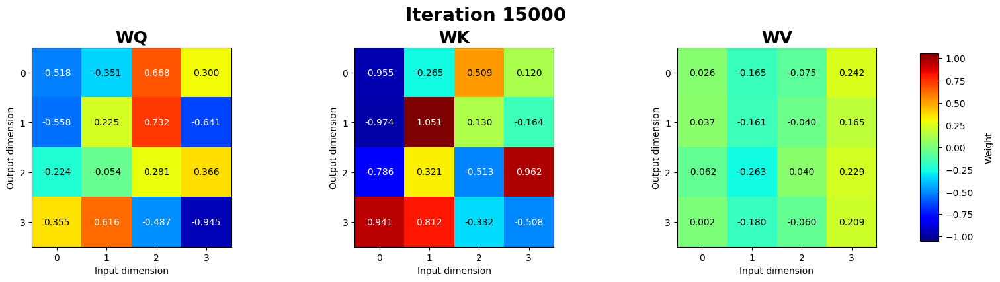

In [11]:
# @title 【STEP５-３】　学習状況の可視化。WQ,WK,WVの様子
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Settings
# ============================================================
history_dir = "/content/nanoGPT/history"

# ============================================================
# Load History Files
# ============================================================
files = sorted(
    glob.glob(
        os.path.join(history_dir, "*.pt")
    )
)

if len(files) == 0:
    raise RuntimeError(
        f"No history files found: {history_dir}"
    )

print("============================================================")
print("WQ / WK / WV HISTORY HEATMAP")
print("============================================================")
print("History directory :", history_dir)
print("Number of files   :", len(files))
print("First             :", os.path.basename(files[0]))
print("Last              :", os.path.basename(files[-1]))

# ============================================================
# Determine Common Color Scale
# ============================================================
vmax = 0.0

for file in files:
    h = torch.load(
        file,
        map_location="cpu"
    )

    for key in ["WQ", "WK", "WV"]:
        if key not in h:
            raise KeyError(
                f"{key} is not found in {file}"
            )

        w = h[key]

        if torch.is_tensor(w):
            w = w.detach().cpu().numpy()

        vmax = max(
            vmax,
            float(np.abs(w).max())
        )

if vmax == 0:
    vmax = 1.0

vmin = -vmax

print("Common color range :",
      f"{vmin:.4f} ～ {vmax:.4f}")

# ============================================================
# Plot Each History
# ============================================================
for history_no, file in enumerate(files):

    h = torch.load(
        file,
        map_location="cpu"
    )

    # --------------------------------------------------------
    # Iteration Number
    # --------------------------------------------------------
    if "iter_num" in h:
        iteration = int(h["iter_num"])
    else:
        basename = os.path.basename(file)

        try:
            iteration = int(
                basename
                .replace("iter_", "")
                .replace(".pt", "")
            )
        except:
            iteration = history_no

    # --------------------------------------------------------
    # WQ / WK / WV
    # --------------------------------------------------------
    matrices = []

    for key in ["WQ", "WK", "WV"]:

        w = h[key]

        if torch.is_tensor(w):
            w = w.detach().cpu().numpy()

        matrices.append(
            (key, w)
        )

    # ========================================================
    # Figure
    # ========================================================
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 4.5)
    )

    # カラーバー用の余白を右側に確保
    fig.subplots_adjust(
        left=0.06,
        right=0.88,
        bottom=0.15,
        top=0.82,
        wspace=0.45
    )

    # ========================================================
    # Heatmaps
    # ========================================================
    for ax, (name, matrix) in zip(
        axes,
        matrices
    ):

        im = ax.imshow(
            matrix,
            cmap="jet",
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            aspect="equal"
        )

        ax.set_title(
            name,
            fontsize=18,
            fontweight="bold"
        )

        ax.set_xlabel(
            "Input dimension"
        )

        ax.set_ylabel(
            "Output dimension"
        )

        ax.set_xticks(
            range(matrix.shape[1])
        )

        ax.set_yticks(
            range(matrix.shape[0])
        )

        # ----------------------------------------------------
        # Numerical Values
        # ----------------------------------------------------
        for i in range(matrix.shape[0]):

            for j in range(matrix.shape[1]):

                value = matrix[i, j]

                # 背景色を取得して文字色を決める
                rgba = im.cmap(
                    im.norm(value)
                )

                brightness = (
                    0.299 * rgba[0]
                    + 0.587 * rgba[1]
                    + 0.114 * rgba[2]
                )

                text_color = (
                    "black"
                    if brightness > 0.55
                    else "white"
                )

                ax.text(
                    j,
                    i,
                    f"{value:.3f}",
                    ha="center",
                    va="center",
                    fontsize=10,
                    color=text_color
                )

    # ========================================================
    # Common Color Bar
    # ========================================================

    # カラーバー専用領域
    cbar_ax = fig.add_axes(
        [0.91, 0.17, 0.018, 0.63]
    )

    cbar = fig.colorbar(
        im,
        cax=cbar_ax
    )

    cbar.set_label(
        "Weight",
        rotation=90,
        labelpad=12
    )

    # ========================================================
    # Main Title
    # ========================================================
    fig.suptitle(
        f"Iteration {iteration}",
        fontsize=20,
        fontweight="bold",
        y=0.96
    )

    plt.show()

In [ ]:
# @title 【STEP7】処理の流れ分析
# ============================================================
# History Loader
# ============================================================

import glob
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties


# ============================================================
# Vocabulary
# ============================================================

vocab = [
        "吾輩",
        "である",
        "名前",
        "まだ",
        "ない",
        "猫",
        "は",
        "。",
        "どこ",
        "で",
        "生れた",
        "か",
        "とんと",
        "見当",
        "が",
        "つかぬ"
    ]

# ============================================================
# Japanese Font
# ============================================================
!apt-get -qq update
!apt-get -qq install -y fonts-noto-cjk

font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
jpfont = FontProperties(fname=font_path)


# ============================================================
# History Loader
# ============================================================

def load_history(history_dir="history"):

    files = sorted(
        glob.glob(os.path.join(history_dir, "*.pt"))
    )

    if len(files) == 0:
        raise RuntimeError(
            f"No history files found in '{history_dir}'."
        )

    history = []

    for f in files:

        d = torch.load(
            f,
            map_location="cpu"
        )

        history.append(d)

    print("----------------------------------------")
    print("History")
    print("----------------------------------------")
    print(f"Directory : {history_dir}")
    print(f"Files     : {len(history)}")
    print(f"First     : {os.path.basename(files[0])}")
    print(f"Last      : {os.path.basename(files[-1])}")
    print()

    return history


# ============================================================
# Initial / Final Parameters
# ============================================================

def print_initial_final(history, vocab):

    first = history[0]
    last  = history[-1]

    print("\n============================================================")
    print("INITIAL / FINAL PARAMETERS")
    print("============================================================")

    # --------------------------------------------------------
    # Word Embedding
    # --------------------------------------------------------

    print("\n============================================================")
    print("Word Embedding")
    print("============================================================")

    emb0 = first["embedding_weight"].numpy()
    emb1 = last["embedding_weight"].numpy()

    for i, word in enumerate(vocab):

        print("----------------------------------------")
        print(word)

        print("Initial")
        print(np.round(emb0[i], 4))

        print("Final")
        print(np.round(emb1[i], 4))

    # --------------------------------------------------------
    # Position Embedding
    # --------------------------------------------------------

    print("\n============================================================")
    print("Position Embedding")
    print("============================================================")

    pos0 = first["position_weight"].numpy()
    pos1 = last["position_weight"].numpy()

    for p in range(pos0.shape[0]):

        print("----------------------------------------")
        print(f"Position {p}")

        print("Initial")
        print(np.round(pos0[p], 4))

        print("Final")
        print(np.round(pos1[p], 4))

    # --------------------------------------------------------
    # Transformer Input
    # --------------------------------------------------------

    print("\n============================================================")
    print("Transformer Input (= Word + Position)")
    print("============================================================")

    for i, word in enumerate(vocab):

        print("----------------------------------------")
        print(word)

        for p in range(pos0.shape[0]):

            x0 = emb0[i] + pos0[p]
            x1 = emb1[i] + pos1[p]

            print(f"\nPosition {p}")

            print("Initial")
            print(np.round(x0, 4))

            print("Final")
            print(np.round(x1, 4))


# ============================================================
# WQ WK WV / Q K V
# ============================================================

def print_qkv(history, vocab):

    first = history[0]
    last  = history[-1]

    # --------------------------------------------------------
    # Initial WQ / WK / WV
    # --------------------------------------------------------

    WQ0 = first["WQ"].numpy()
    WK0 = first["WK"].numpy()
    WV0 = first["WV"].numpy()

    # --------------------------------------------------------
    # Final WQ / WK / WV
    # --------------------------------------------------------

    WQ1 = last["WQ"].numpy()
    WK1 = last["WK"].numpy()
    WV1 = last["WV"].numpy()

    # --------------------------------------------------------
    # WQ
    # --------------------------------------------------------

    print("\n============================================================")
    print("WQ")
    print("============================================================")

    print("\nInitial")
    print(np.round(WQ0, 4))

    print("\nFinal")
    print(np.round(WQ1, 4))

    # --------------------------------------------------------
    # WK
    # --------------------------------------------------------

    print("\n============================================================")
    print("WK")
    print("============================================================")

    print("\nInitial")
    print(np.round(WK0, 4))

    print("\nFinal")
    print(np.round(WK1, 4))

    # --------------------------------------------------------
    # WV
    # --------------------------------------------------------

    print("\n============================================================")
    print("WV")
    print("============================================================")

    print("\nInitial")
    print(np.round(WV0, 4))

    print("\nFinal")
    print(np.round(WV1, 4))

    # --------------------------------------------------------
    # Embedding / Position
    # --------------------------------------------------------

    emb0 = first["embedding_weight"].numpy()
    emb1 = last["embedding_weight"].numpy()

    pos0 = first["position_weight"].numpy()
    pos1 = last["position_weight"].numpy()

    # --------------------------------------------------------
    # Q / K / V
    # --------------------------------------------------------

    print("\n============================================================")
    print("Q / K / V")
    print("============================================================")

    for i, word in enumerate(vocab):

        print("============================================================")
        print(word)
        print("============================================================")

        for p in range(pos0.shape[0]):

            print("----------------------------------------")
            print(f"Position {p}")

            # =================================================
            # Initial
            # =================================================

            x0 = emb0[i] + pos0[p]

            Q0 = x0 @ WQ0.T
            K0 = x0 @ WK0.T
            V0 = x0 @ WV0.T

            # =================================================
            # Final
            # =================================================

            x1 = emb1[i] + pos1[p]

            Q1 = x1 @ WQ1.T
            K1 = x1 @ WK1.T
            V1 = x1 @ WV1.T

            # -------------------------------------------------
            # Q
            # -------------------------------------------------

            print("\nQ")

            print("Initial")
            print(np.round(Q0, 4))

            print("Final")
            print(np.round(Q1, 4))

            # -------------------------------------------------
            # K
            # -------------------------------------------------

            print("\nK")

            print("Initial")
            print(np.round(K0, 4))

            print("Final")
            print(np.round(K1, 4))

            # -------------------------------------------------
            # V
            # -------------------------------------------------

            print("\nV")

            print("Initial")
            print(np.round(V0, 4))

            print("Final")
            print(np.round(V1, 4))


# ============================================================
# Attention / Probability
# ============================================================

def print_attention_probability(history, vocab):

    last = history[-1]

    # --------------------------------------------------------
    # Attention
    # --------------------------------------------------------

    if "Attention" in last:

        att = last["Attention"]

        if torch.is_tensor(att):
            att = att.detach().cpu().numpy()

        while att.ndim > 2:
            att = att[0]

        print("\n============================================================")
        print("Attention")
        print("============================================================")

        print(np.round(att, 4))

        plt.figure(figsize=(6, 5))

        plt.imshow(
            att,
            cmap="jet",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        plt.colorbar()

        plt.xticks(
            range(len(vocab)),
            vocab,
            rotation=90,
            fontproperties=jpfont
        )

        plt.yticks(
            range(len(vocab)),
            vocab,
            fontproperties=jpfont
        )

        plt.title(
            "Attention Matrix",
            fontproperties=jpfont
        )

        # 数値をヒートマップ内に表示

        for y in range(att.shape[0]):

            for x in range(att.shape[1]):

                c = "white" if att[y, x] > 0.5 else "black"

                plt.text(
                    x,
                    y,
                    f"{att[y, x]:.2f}",
                    ha="center",
                    va="center",
                    color=c,
                    fontsize=9,
                    fontweight="bold"
                )

        plt.tight_layout()
        plt.show()

    # --------------------------------------------------------
    # Probability
    # --------------------------------------------------------

    if "Probability" in last:

        prob = last["Probability"]

        if torch.is_tensor(prob):
            prob = prob.detach().cpu().numpy()

        if prob.ndim == 3:
            prob = prob[0, -1]

        elif prob.ndim == 2:
            prob = prob[-1]

        pred = np.argmax(prob)

        print("\n============================================================")
        print("Probability")
        print("============================================================")

        for i, p in enumerate(prob):

            print(
                f"{i:2d} {vocab[i]:8s} {p:.5f}"
            )

        plt.figure(figsize=(8, 5))

        colors = ["skyblue"] * len(prob)
        colors[pred] = "crimson"

        bars = plt.barh(
            range(len(prob)),
            prob,
            color=colors,
            edgecolor="black"
        )

        plt.gca().invert_yaxis()

        plt.xlim(0, 1)

        plt.yticks(
            range(len(vocab)),
            vocab,
            fontproperties=jpfont
        )

        plt.xlabel(
            "Probability",
            fontproperties=jpfont
        )

        plt.title(
            "Next Token Probability",
            fontproperties=jpfont
        )

        for b, v in zip(bars, prob):

            plt.text(
                v + 0.01,
                b.get_y() + b.get_height() / 2,
                f"{v:.4f}",
                va="center",
                fontsize=10,
                fontproperties=jpfont
            )

        plt.grid(
            axis="x",
            alpha=0.3
        )

        plt.tight_layout()
        plt.show()

        print()
        print("Prediction :", vocab[pred])


# ============================================================
# Generation Demo
# ============================================================

def generation_demo():

    from model import GPT, GPTConfig

    device = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    out_dir = "out"

    # --------------------------------------------------------
    # Prompt
    # --------------------------------------------------------

    prompt = "吾輩 は 猫"

    temperature = 1.0

    max_new_tokens = 20



    stoi = {
        w: i
        for i, w in enumerate(vocab)
    }

    itos = {
        i: w
        for w, i in stoi.items()
    }

    def encode(text):

        return [
            stoi[t]
            for t in text.split()
        ]

    def decode(ids):

        return " ".join(
            itos[int(i)]
            for i in ids
        )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    checkpoint = torch.load(
        os.path.join(
            out_dir,
            "ckpt.pt"
        ),
        map_location=device
    )

    model = GPT(
        GPTConfig(
            **checkpoint["model_args"]
        )
    )

    state = checkpoint["model"]

    # compile=Trueで保存された場合への対応

    unwanted_prefix = "_orig_mod."

    for k in list(state.keys()):

        if k.startswith(unwanted_prefix):

            state[
                k[len(unwanted_prefix):]
            ] = state.pop(k)

    model.load_state_dict(state)

    model.eval()

    model.to(device)

    # --------------------------------------------------------
    # Prompt -> token ID
    # --------------------------------------------------------

    x = torch.tensor(
        encode(prompt),
        dtype=torch.long,
        device=device
    )[None, ...]

    idx = x.clone()

    print()
    print("============================================================")
    print("Generation")
    print("============================================================")

    # --------------------------------------------------------
    # Greedy Generation
    # --------------------------------------------------------

    with torch.no_grad():

        for step in range(max_new_tokens):

            logits, _ = model(
                idx[
                    :,
                    -model.config.block_size:
                ]
            )

            probs = torch.softmax(
                logits[:, -1] / temperature,
                dim=-1
            )

            print("----------------------------------------")
            print(f"Step {step + 1}")

            print(
                decode(
                    idx[0].tolist()
                )
            )

            p = probs[0].cpu().numpy()

            pred = np.argmax(p)

            print(
                "Prediction :",
                itos[pred]
            )

            # Greedy decoding

            idx_next = torch.argmax(
                probs,
                dim=-1,
                keepdim=True
            )

            idx = torch.cat(
                (
                    idx,
                    idx_next
                ),
                dim=1
            )

    print()
    print("============================================================")
    print("Generated")
    print("============================================================")

    print(
        decode(
            idx[0].tolist()
        )
    )


# ============================================================
# main
# ============================================================

def main():

    history = load_history()

    print_initial_final(
        history,
        vocab
    )

    print_qkv(
        history,
        vocab
    )

    print_attention_probability(
        history,
        vocab
    )

    generation_demo()


# ============================================================
# Execute
# ============================================================

if __name__ == "__main__":

    main()

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
----------------------------------------
History
----------------------------------------
Directory : history
Files     : 76
First     : iter_000000.pt
Last      : iter_015000.pt


INITIAL / FINAL PARAMETERS

Word Embedding
----------------------------------------
吾輩
Initial
[-0.0073  0.0197  0.0472 -0.0258]
Final
[ 0.4596  0.9031  0.2518 -0.7108]
----------------------------------------
である
Initial
[ 0.0122  0.0022  0.0003 -0.0213]
Final
[-1.2856  0.3756  0.9886 -0.0237]
----------------------------------------
名前
Initial
[ 0.0134 -0.0159 -0.0211  0.0137]
Final
[ 0.6846 -0.3926 -0.265  -0.5854]
----------------------------------------
まだ
Initial
[ 0.0104  0.0106 -0.0113  0.0008]
Final
[-0.5736  0.8363 -0.6929 -0.8133]
----------------------------------------
ない
Initial
[0.0043 0.0329 0.0196 0.0507]


In [ ]:
# @title 【STEP８】モデルパラメータの確認
from pathlib import Path
import torch
from model import GPT, GPTConfig

# ============================================================
# Checkpoint
# ============================================================
ckpt = Path("/content/nanoGPT/out/ckpt.pt")

print("============================================================")
print("CHECKPOINT")
print("============================================================")
print("Path   :", ckpt)
print("Exists :", ckpt.exists())

if not ckpt.exists():
    raise FileNotFoundError(
        f"checkpoint が見つかりません: {ckpt}"
    )

# ============================================================
# Load Checkpoint
# ============================================================
checkpoint = torch.load(
    ckpt,
    map_location="cpu"
)

print()
print("Checkpoint loaded.")

# ============================================================
# Check Checkpoint Contents
# ============================================================
print()
print("============================================================")
print("CHECKPOINT CONTENTS")
print("============================================================")

print("Keys:")
for key in checkpoint.keys():
    print(" ", key)

print()
print("iter_num      =", checkpoint.get("iter_num"))
print("best_val_loss =", checkpoint.get("best_val_loss"))

# ============================================================
# Model Arguments
# ============================================================
if "model_args" not in checkpoint:
    raise KeyError(
        "checkpoint に model_args がありません。"
    )

model_args = checkpoint["model_args"]

print()
print("============================================================")
print("MODEL ARGS")
print("============================================================")

for key, value in model_args.items():
    print(f"{key:12s} = {value}")

# ============================================================
# Create Model
# ============================================================
model = GPT(
    GPTConfig(**model_args)
)

# ============================================================
# Load State Dict
# ============================================================
if "model" not in checkpoint:
    raise KeyError(
        "checkpoint に model がありません。"
    )

state_dict = checkpoint["model"]

# torch.compile() で保存されたcheckpointでは
# parameter名に "_orig_mod." が付く場合があるので除去する
new_state = {}

for key, value in state_dict.items():
    if key.startswith("_orig_mod."):
        key = key[len("_orig_mod."):]
    new_state[key] = value

# ============================================================
# Set Model Parameters
# ============================================================
model.load_state_dict(new_state)

# ============================================================
# Evaluation Mode
# ============================================================
model.eval()

# ============================================================
# Model Information
# ============================================================
print()
print("============================================================")
print("MODEL")
print("============================================================")
print("Model loaded successfully.")
print()

num_params = sum(
    p.numel()
    for p in model.parameters()
)

num_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Parameters           = {num_params:,}")
print(f"Trainable parameters = {num_trainable_params:,}")

# ============================================================
# Parameter Names and Shapes
# ============================================================
print()
print("============================================================")
print("PARAMETER SHAPES")
print("============================================================")

for name, param in model.named_parameters():
    print(
        f"{name:45s} {str(tuple(param.shape)):15s}"
    )

# ============================================================
# Word Embedding
# ============================================================
embedding_weight = (
    model.transformer.wte.weight
    .detach()
    .cpu()
)

print()
print("============================================================")
print("WORD EMBEDDING")
print("============================================================")
print("shape =", tuple(embedding_weight.shape))
print(embedding_weight)

# ============================================================
# Position Embedding
# ============================================================
position_weight = (
    model.transformer.wpe.weight
    .detach()
    .cpu()
)

print()
print("============================================================")
print("POSITION EMBEDDING")
print("============================================================")
print("shape =", tuple(position_weight.shape))
print(position_weight)

# ============================================================
# Q / K / V Weight
# ============================================================
if model.config.n_layer > 0:
    qkv_weight = (
        model.transformer.h[0]
        .attn
        .c_attn
        .weight
        .detach()
        .cpu()
    )

    n_embd = model.config.n_embd

    WQ, WK, WV = qkv_weight.split(
        n_embd,
        dim=0
    )

    print()
    print("============================================================")
    print("WQ")
    print("============================================================")
    print("shape =", tuple(WQ.shape))
    print(WQ)

    print()
    print("============================================================")
    print("WK")
    print("============================================================")
    print("shape =", tuple(WK.shape))
    print(WK)

    print()
    print("============================================================")
    print("WV")
    print("============================================================")
    print("shape =", tuple(WV.shape))
    print(WV)

# ============================================================
# Q / K / V Bias
# ============================================================
if (
    model.config.n_layer > 0
    and model.transformer.h[0].attn.c_attn.bias is not None
):
    qkv_bias = (
        model.transformer.h[0]
        .attn
        .c_attn
        .bias
        .detach()
        .cpu()
    )

    bQ, bK, bV = qkv_bias.split(
        model.config.n_embd,
        dim=0
    )

    print()
    print("============================================================")
    print("Q / K / V BIAS")
    print("============================================================")
    print("bQ =", bQ)
    print("bK =", bK)
    print("bV =", bV)

# ============================================================
# Attention Output Projection
# ============================================================
if model.config.n_layer > 0:
    WO = (
        model.transformer.h[0]
        .attn
        .c_proj
        .weight
        .detach()
        .cpu()
    )

    print()
    print("============================================================")
    print("WO")
    print("============================================================")
    print("shape =", tuple(WO.shape))
    print(WO)

# ============================================================
# LayerNorm
# ============================================================
if model.config.n_layer > 0:
    ln1_weight = (
        model.transformer.h[0]
        .ln_1
        .weight
        .detach()
        .cpu()
    )

    ln2_weight = (
        model.transformer.h[0]
        .ln_2
        .weight
        .detach()
        .cpu()
    )

    print()
    print("============================================================")
    print("LAYERNORM")
    print("============================================================")
    print("LN1 weight =", ln1_weight)

    if model.transformer.h[0].ln_1.bias is not None:
        print(
            "LN1 bias   =",
            model.transformer.h[0]
            .ln_1
            .bias
            .detach()
            .cpu()
        )

    print()
    print("LN2 weight =", ln2_weight)

    if model.transformer.h[0].ln_2.bias is not None:
        print(
            "LN2 bias   =",
            model.transformer.h[0]
            .ln_2
            .bias
            .detach()
            .cpu()
        )

# ============================================================
# MLP
# ============================================================
if model.config.n_layer > 0:
    mlp_fc_weight = (
        model.transformer.h[0]
        .mlp
        .c_fc
        .weight
        .detach()
        .cpu()
    )

    mlp_proj_weight = (
        model.transformer.h[0]
        .mlp
        .c_proj
        .weight
        .detach()
        .cpu()
    )

    print()
    print("============================================================")
    print("MLP")
    print("============================================================")

    print("c_fc.weight")
    print("shape =", tuple(mlp_fc_weight.shape))
    print(mlp_fc_weight)

    print()
    print("c_proj.weight")
    print("shape =", tuple(mlp_proj_weight.shape))
    print(mlp_proj_weight)

# ============================================================
# Final LayerNorm
# ============================================================
lnf_weight = (
    model.transformer.ln_f.weight
    .detach()
    .cpu()
)

print()
print("============================================================")
print("FINAL LAYERNORM")
print("============================================================")
print("weight =", lnf_weight)

if model.transformer.ln_f.bias is not None:
    print(
        "bias   =",
        model.transformer.ln_f.bias
        .detach()
        .cpu()
    )

# ============================================================
# Finished
# ============================================================
print()
print("============================================================")
print("READY")
print("============================================================")
print("Model loaded successfully.")
print("The model is ready for analysis.")

CHECKPOINT
Path   : /content/nanoGPT/out/ckpt.pt
Exists : True

Checkpoint loaded.

CHECKPOINT CONTENTS
Keys:
  model
  optimizer
  model_args
  iter_num
  best_val_loss
  config

iter_num      = 15000
best_val_loss = tensor(0.0908)

MODEL ARGS
n_layer      = 1
n_head       = 1
n_embd       = 4
block_size   = 5
bias         = True
vocab_size   = 16
dropout      = 0.0
number of parameters: 0.00M

MODEL
Model loaded successfully.

Parameters           = 336
Trainable parameters = 336

PARAMETER SHAPES
transformer.wte.weight                        (16, 4)        
transformer.wpe.weight                        (5, 4)         
transformer.h.0.ln_1.weight                   (4,)           
transformer.h.0.ln_1.bias                     (4,)           
transformer.h.0.attn.c_attn.weight            (12, 4)        
transformer.h.0.attn.c_attn.bias              (12,)          
transformer.h.0.attn.c_proj.weight            (4, 4)         
transformer.h.0.attn.c_proj.bias              (4,)           

In [ ]:
# @title 【STEP９】文書生成
import os
import torch
from model import GPT, GPTConfig

# ============================================================
# Settings
# ============================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
ckpt_path = "/content/nanoGPT/out/ckpt.pt"

# ============================================================
# Vocabulary
# ============================================================
vocab = [
    "吾輩",
    "である",
    "名前",
    "まだ",
    "ない",
    "猫",
    "は",
    "。",
    "どこ",
    "で",
    "生れた",
    "か",
    "とんと",
    "見当",
    "が",
    "つかぬ"
]

stoi = {w: i for i, w in enumerate(vocab)}
itos = {i: w for w, i in stoi.items()}

# ============================================================
# Prompt
# ============================================================
prompt_tokens = [
    "吾輩"
]

# ============================================================
# Generation Settings
# ============================================================
max_new_tokens = 30

# False: 確率分布からサンプリング
# True : 最大確率tokenを常に選択
#greedy = False
greedy=True

# Sampling時のみ使用
temperature = 1.0

# NoneならTop-kを使用しない
# 例: 3なら確率上位3 tokenだけを候補にする
top_k = None

# 1.0ならTop-pを使用しない
# 例: 0.9
top_p = 1.0

# 再現性を持たせたい場合
seed = 42

torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)

# ============================================================
# Checkpoint Check
# ============================================================
if not os.path.exists(ckpt_path):
    raise FileNotFoundError(
        f"checkpoint がありません: {ckpt_path}"
    )

# ============================================================
# Load Checkpoint
# ============================================================
checkpoint = torch.load(
    ckpt_path,
    map_location=device
)

# ============================================================
# Create Model
# ============================================================
model = GPT(
    GPTConfig(**checkpoint["model_args"])
)

# ============================================================
# State Dict
# ============================================================
state = checkpoint["model"]

new_state = {}

for k, v in state.items():

    if k.startswith("_orig_mod."):
        k = k[len("_orig_mod."):]

    new_state[k] = v

model.load_state_dict(new_state)

model.to(device)
model.eval()

# ============================================================
# Model Information
# ============================================================
print("============================================================")
print("MODEL")
print("============================================================")
print("checkpoint  =", ckpt_path)
print("device      =", device)
print("block_size  =", model.config.block_size)
print("vocab_size  =", model.config.vocab_size)
print("n_layer     =", model.config.n_layer)
print("n_head      =", model.config.n_head)
print("n_embd      =", model.config.n_embd)

# ============================================================
# Check Vocabulary Size
# ============================================================
if len(vocab) != model.config.vocab_size:

    raise ValueError(
        f"vocab size mismatch: "
        f"vocab={len(vocab)}, "
        f"model={model.config.vocab_size}"
    )

# ============================================================
# Prompt -> Token IDs
# ============================================================
for token in prompt_tokens:

    if token not in stoi:

        raise ValueError(
            f"語彙にないtokenです: {token}"
        )

prompt_ids = [
    stoi[token]
    for token in prompt_tokens
]

idx = torch.tensor(
    [prompt_ids],
    dtype=torch.long,
    device=device
)

generated_tokens = prompt_tokens.copy()

# ============================================================
# Generation Information
# ============================================================
print()
print("============================================================")
print("GENERATION SETTINGS")
print("============================================================")
print("Prompt         =", "".join(prompt_tokens))
print("max_new_tokens =", max_new_tokens)
print("greedy         =", greedy)

if greedy:

    print("temperature    = not used")
    print("top_k          = not used")
    print("top_p          = not used")

else:

    print("temperature    =", temperature)
    print("top_k          =", top_k)
    print("top_p          =", top_p)

print()

# ============================================================
# Generation
# ============================================================
with torch.no_grad():

    for step in range(max_new_tokens):

        # ----------------------------------------------------
        # Context
        # ----------------------------------------------------
        idx_cond = idx[
            :,
            -model.config.block_size:
        ]

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------
        logits, _ = model(idx_cond)

        # 最後の位置の次token logits
        logits = logits[
            :,
            -1,
            :
        ]

        # ====================================================
        # Greedy Decoding
        # ====================================================
        if greedy:

            idx_next = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        # ====================================================
        # Sampling
        # ====================================================
        else:

            if temperature <= 0:

                raise ValueError(
                    "temperature は0より大きくしてください。"
                )

            # ------------------------------------------------
            # Temperature
            # ------------------------------------------------
            logits = logits / temperature

            # ------------------------------------------------
            # Top-k
            # ------------------------------------------------
            if top_k is not None:

                k = min(
                    top_k,
                    logits.size(-1)
                )

                values, _ = torch.topk(
                    logits,
                    k
                )

                threshold = values[
                    :,
                    [-1]
                ]

                logits = logits.masked_fill(
                    logits < threshold,
                    float("-inf")
                )

            # ------------------------------------------------
            # Probability
            # ------------------------------------------------
            probs = torch.softmax(
                logits,
                dim=-1
            )

            # ------------------------------------------------
            # Top-p
            # ------------------------------------------------
            if top_p < 1.0:

                sorted_probs, sorted_indices = torch.sort(
                    probs,
                    descending=True,
                    dim=-1
                )

                cumulative_probs = torch.cumsum(
                    sorted_probs,
                    dim=-1
                )

                remove = (
                    cumulative_probs > top_p
                )

                remove[:, 1:] = (
                    remove[:, :-1].clone()
                )

                remove[:, 0] = False

                sorted_probs = sorted_probs.masked_fill(
                    remove,
                    0.0
                )

                sorted_probs = (
                    sorted_probs
                    /
                    sorted_probs.sum(
                        dim=-1,
                        keepdim=True
                    )
                )

                sampled_index = torch.multinomial(
                    sorted_probs,
                    num_samples=1
                )

                idx_next = sorted_indices.gather(
                    dim=-1,
                    index=sampled_index
                )

            else:

                idx_next = torch.multinomial(
                    probs,
                    num_samples=1
                )

        # ====================================================
        # Generated Token
        # ====================================================
        next_id = int(
            idx_next[0, 0].item()
        )

        next_token = itos[next_id]

        generated_tokens.append(
            next_token
        )

        # ----------------------------------------------------
        # Append Token
        # ----------------------------------------------------
        idx = torch.cat(
            (
                idx,
                idx_next
            ),
            dim=1
        )

        print(
            f"Step {step + 1:2d}: {next_token}"
        )

# ============================================================
# Result
# ============================================================
print()
print("============================================================")
print("GENERATED TEXT")
print("============================================================")

generated_text = "".join(
    generated_tokens
)

print(generated_text)

number of parameters: 0.00M
MODEL
checkpoint  = /content/nanoGPT/out/ckpt.pt
device      = cuda
block_size  = 5
vocab_size  = 16
n_layer     = 1
n_head      = 1
n_embd      = 4

GENERATION SETTINGS
Prompt         = 吾輩
max_new_tokens = 30
greedy         = True
temperature    = not used
top_k          = not used
top_p          = not used

Step  1: は
Step  2: 猫
Step  3: である
Step  4: 。
Step  5: 名前
Step  6: は
Step  7: まだ
Step  8: ない
Step  9: 。
Step 10: どこ
Step 11: で
Step 12: 生れた
Step 13: か
Step 14: とんと
Step 15: 見当
Step 16: が
Step 17: つかぬ
Step 18: 。
Step 19: 吾輩
Step 20: は
Step 21: 猫
Step 22: である
Step 23: 。
Step 24: 名前
Step 25: は
Step 26: まだ
Step 27: ない
Step 28: 。
Step 29: どこ
Step 30: で

GENERATED TEXT
吾輩は猫である。名前はまだない。どこで生れたかとんと見当がつかぬ。吾輩は猫である。名前はまだない。どこで


## 付録　学習済パラメータの確認

In [ ]:
# @title
# ============================================================
# visualize_forward.py
# 教材用
# 学習済みTransformer内部計算表示
#
# model_class2.py 使用
# historyは使用しない
# ckpt.ptのみ使用
# ============================================================

import os
import pickle
import numpy as np
import torch

# ============================================================
# nanoGPT directory
# ============================================================

NANOGPT_DIR = "/content/nanoGPT"

if not os.path.isdir(NANOGPT_DIR):
    raise FileNotFoundError(
        f"nanoGPT directory not found: {NANOGPT_DIR}"
    )

os.chdir(NANOGPT_DIR)

print("Current directory =", os.getcwd())

# ============================================================
# 可視化対応モデル
# ============================================================

from model_class2 import GPTConfig
from model_class2 import GPT

print("GPT loaded from model_class2.py")
print(
    "enable_visualization =",
    hasattr(GPT, "enable_visualization")
)

if not hasattr(GPT, "enable_visualization"):
    raise RuntimeError(
        "model_class2.py に enable_visualization() がありません。"
    )

# ============================================================
# 設定
# ============================================================

device = "cpu"

out_dir = "/content/nanoGPT/out"

checkpoint = os.path.join(
    out_dir,
    "ckpt.pt"
)

meta_path = "/content/nanoGPT/data/jp/meta.pkl"

# ============================================================
# ファイル確認
# ============================================================

print()
print("========================================")
print("FILE CHECK")
print("========================================")
print("checkpoint =", checkpoint)
print("exists     =", os.path.exists(checkpoint))
print("meta.pkl   =", meta_path)
print("exists     =", os.path.exists(meta_path))

if not os.path.exists(checkpoint):
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint}"
    )

if not os.path.exists(meta_path):
    raise FileNotFoundError(
        f"meta.pkl not found: {meta_path}"
    )

# ============================================================
# checkpoint 読み込み
# ============================================================

print()
print("========================================")
print("LOAD CHECKPOINT")
print("========================================")

ckpt = torch.load(
    checkpoint,
    map_location=device
)

print("checkpoint loaded")

if "model_args" not in ckpt:
    raise KeyError(
        "ckpt.pt に model_args がありません。"
    )

if "model" not in ckpt:
    raise KeyError(
        "ckpt.pt に model がありません。"
    )

print("model_args =", ckpt["model_args"])

# ============================================================
# モデル生成
# ============================================================

gptconf = GPTConfig(
    **ckpt["model_args"]
)

model = GPT(gptconf)

state_dict = ckpt["model"]

# torch.compile 使用時のprefixを除去
unwanted_prefix = "_orig_mod."

for k, v in list(state_dict.items()):

    if k.startswith(unwanted_prefix):

        state_dict[
            k[len(unwanted_prefix):]
        ] = state_dict.pop(k)

# ============================================================
# 学習済みweight読み込み
# ============================================================

model.load_state_dict(
    state_dict,
    strict=True
)

model.eval()
model.to(device)

print("checkpoint weights loaded")
print(
    "number of parameters =",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

# ============================================================
# vocabulary
# ============================================================

with open(meta_path, "rb") as f:
    meta = pickle.load(f)

if "stoi" not in meta:
    raise KeyError(
        "meta.pkl に stoi がありません。"
    )

if "itos" not in meta:
    raise KeyError(
        "meta.pkl に itos がありません。"
    )

stoi = meta["stoi"]
itos = meta["itos"]

# itosがdictでもlistでも使えるようにする
if isinstance(itos, dict):

    vocab = [
        itos[i]
        for i in range(len(itos))
    ]

else:

    vocab = list(itos)

print()
print("========================================")
print("VOCABULARY")
print("========================================")

for i, token in enumerate(vocab):

    print(
        f"{i:3d} : {token}"
    )

print()
print(
    "vocab size =",
    len(vocab)
)

# ============================================================
# 入力文字列 → Token ID
# ============================================================

def encode_input_text(text, stoi):

    tokens = text.strip().split()

    if len(tokens) == 0:

        raise ValueError(
            "入力が空です。"
        )

    unknown = [
        token
        for token in tokens
        if token not in stoi
    ]

    if len(unknown) != 0:

        raise ValueError(
            "語彙に存在しません : "
            + ", ".join(unknown)
        )

    ids = [
        stoi[token]
        for token in tokens
    ]

    return tokens, ids

# ============================================================
# Tensor取得
# ============================================================

def get_tensor(vd, key):

    if key not in vd:

        print()
        print(
            "visual_data keys =",
            list(vd.keys())
        )

        raise KeyError(
            f"visual_data に '{key}' がありません。"
        )

    x = vd[key]

    while isinstance(x, list):

        if len(x) == 0:
            raise ValueError(
                f"{key} が空のlistです。"
            )

        x = x[0]

    if not torch.is_tensor(x):

        x = torch.tensor(x)

    # batch dimension
    while (
        x.ndim >= 3
        and x.shape[0] == 1
    ):

        x = x[0]

    # 1 headモデルの場合head dimensionを除去
    while (
        x.ndim >= 3
        and x.shape[0] == 1
    ):

        x = x[0]

    return x.detach().cpu()

# ============================================================
# Forward
# ============================================================

def run_forward(text):

    tokens, ids = encode_input_text(
        text,
        stoi
    )

    if len(ids) > model.config.block_size:

        raise ValueError(
            "入力Token数がblock_sizeを超えています。"
        )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device
    )

    model.enable_visualization(True)

    with torch.no_grad():

        logits, _ = model(x)

    vd = model.visual_data

    print()
    print("========================================")
    print("INPUT")
    print("========================================")
    print("text   =", text)
    print("tokens =", tokens)
    print("ids    =", ids)

    print()
    print("========================================")
    print("VISUAL DATA")
    print("========================================")

    for key in vd.keys():

        value = vd[key]

        if torch.is_tensor(value):

            print(
                f"{key:25s}",
                tuple(value.shape)
            )

        elif isinstance(value, dict):

            print(
                f"{key:25s}",
                "(dict)"
            )

        else:

            print(
                f"{key:25s}",
                type(value)
            )

    return tokens, ids, vd

# ============================================================
# Token Embedding
# ============================================================

def show_embedding(tokens, vd):

    emb = get_tensor(
        vd,
        "token_embedding"
    )

    print()
    print("============================================================")
    print("TOKEN EMBEDDING")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                emb[i].numpy(),
                4
            )
        )

# ============================================================
# Position Embedding
# ============================================================

def show_position_embedding(tokens, vd):

    pos = get_tensor(
        vd,
        "position_embedding"
    )

    print()
    print("============================================================")
    print("POSITION EMBEDDING")
    print("============================================================")

    for i in range(len(tokens)):

        print("----------------------------------------")
        print(f"Position {i}")

        print(
            np.round(
                pos[i].numpy(),
                4
            )
        )

# ============================================================
# Token Embedding + Position Embedding
# ============================================================

def show_embedding_sum(tokens, vd):

    x = get_tensor(
        vd,
        "embedding"
    )

    print()
    print("============================================================")
    print("TOKEN EMBEDDING + POSITION EMBEDDING")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# LayerNorm 1
# ============================================================

def show_ln1(tokens, vd):

    ln = get_tensor(
        vd,
        "ln1"
    )

    print()
    print("============================================================")
    print("LAYER NORM 1")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                ln[i].numpy(),
                4
            )
        )

# ============================================================
# WQ
# ============================================================

def show_WQ(vd):

    WQ = get_tensor(
        vd,
        "WQ"
    )

    print()
    print("============================================================")
    print("WQ")
    print("============================================================")

    print(
        np.round(
            WQ.numpy(),
            4
        )
    )

# ============================================================
# WK
# ============================================================

def show_WK(vd):

    WK = get_tensor(
        vd,
        "WK"
    )

    print()
    print("============================================================")
    print("WK")
    print("============================================================")

    print(
        np.round(
            WK.numpy(),
            4
        )
    )

# ============================================================
# WV
# ============================================================

def show_WV(vd):

    WV = get_tensor(
        vd,
        "WV"
    )

    print()
    print("============================================================")
    print("WV")
    print("============================================================")

    print(
        np.round(
            WV.numpy(),
            4
        )
    )

# ============================================================
# Q / K / V bias
# ============================================================

def show_QKV_bias():

    attn = model.transformer.h[0].attn

    if attn.c_attn.bias is None:
        print()
        print("============================================================")
        print("Q / K / V BIAS")
        print("============================================================")
        print("c_attn.bias = None")
        return

    b = attn.c_attn.bias.detach().cpu()
    n_embd = model.config.n_embd

    if b.numel() != 3 * n_embd:
        raise ValueError(
            f"Unexpected c_attn.bias size: {b.numel()} "
            f"(expected {3*n_embd})"
        )

    bQ, bK, bV = b.split(n_embd, dim=0)

    print()
    print("============================================================")
    print("bQ")
    print("============================================================")
    print("shape =", tuple(bQ.shape))
    print(np.round(bQ.numpy(), 4))

    print()
    print("============================================================")
    print("bK")
    print("============================================================")
    print("shape =", tuple(bK.shape))
    print(np.round(bK.numpy(), 4))

    print()
    print("============================================================")
    print("bV")
    print("============================================================")
    print("shape =", tuple(bV.shape))
    print(np.round(bV.numpy(), 4))


# ============================================================
# WO
# ============================================================

def show_WO(vd):

    WO = get_tensor(
        vd,
        "WO"
    )

    print()
    print("============================================================")
    print("WO")
    print("============================================================")

    print(
        np.round(
            WO.numpy(),
            4
        )
    )

# ============================================================
# Q
# ============================================================

def show_Q(tokens, vd):

    q = get_tensor(
        vd,
        "q"
    )

    print()
    print("============================================================")
    print("Q")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                q[i].numpy(),
                4
            )
        )

# ============================================================
# K
# ============================================================

def show_K(tokens, vd):

    k = get_tensor(
        vd,
        "k"
    )

    print()
    print("============================================================")
    print("K")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                k[i].numpy(),
                4
            )
        )

# ============================================================
# V
# ============================================================

def show_V(tokens, vd):

    v = get_tensor(
        vd,
        "v"
    )

    print()
    print("============================================================")
    print("V")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                v[i].numpy(),
                4
            )
        )

# ============================================================
# Attention Score
# Q K^T / sqrt(dk)
# ============================================================

def show_attention_score(tokens, vd):

    score = get_tensor(
        vd,
        "attention_score"
    )

    print()
    print("============================================================")
    print("ATTENTION SCORE")
    print("Q K^T / sqrt(dk)")
    print("============================================================")

    print(
        "        ",
        " ".join(
            f"{t:>8s}"
            for t in tokens
        )
    )

    for i, token in enumerate(tokens):

        values = " ".join(
            f"{x.item():8.4f}"
            for x in score[i]
        )

        print(
            f"{token:>8s} {values}"
        )

# ============================================================
# Masked Score
# ============================================================

def show_masked_score(tokens, vd):

    score = get_tensor(
        vd,
        "masked_score"
    )

    print()
    print("============================================================")
    print("MASKED ATTENTION SCORE")
    print("============================================================")

    print(
        "        ",
        " ".join(
            f"{t:>8s}"
            for t in tokens
        )
    )

    for i, token in enumerate(tokens):

        values = []

        for x in score[i]:

            if torch.isinf(x):

                values.append(
                    f"{'-inf':>8s}"
                )

            else:

                values.append(
                    f"{x.item():8.4f}"
                )

        print(
            f"{token:>8s} "
            + " ".join(values)
        )

# ============================================================
# Attention Probability
# ============================================================

def show_attention_probability(tokens, vd):

    prob = get_tensor(
        vd,
        "attention"
    )

    print()
    print("============================================================")
    print("ATTENTION PROBABILITY")
    print("Softmax(Masked Score)")
    print("============================================================")

    print(
        "        ",
        " ".join(
            f"{t:>8s}"
            for t in tokens
        )
    )

    for i, token in enumerate(tokens):

        values = " ".join(
            f"{x.item():8.4f}"
            for x in prob[i]
        )

        print(
            f"{token:>8s} {values}"
        )

# ============================================================
# Context Vector
# ============================================================

def show_context(tokens, vd):

    context = get_tensor(
        vd,
        "context"
    )

    print()
    print("============================================================")
    print("CONTEXT VECTOR")
    print("Attention Probability × V")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                context[i].numpy(),
                4
            )
        )

# ============================================================
# WO Output
# ============================================================

def show_attention_output(tokens, vd):

    y = get_tensor(
        vd,
        "attn_output"
    )

    print()
    print("============================================================")
    print("ATTENTION OUTPUT")
    print("Context × WO")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                y[i].numpy(),
                4
            )
        )

# ============================================================
# Residual 1
# ============================================================

def show_residual1(tokens, vd):

    r = get_tensor(
        vd,
        "residual1"
    )

    print()
    print("============================================================")
    print("RESIDUAL 1")
    print("Embedding + Attention Output")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                r[i].numpy(),
                4
            )
        )

# ============================================================
# LayerNorm 2
# ============================================================

def show_ln2(tokens, vd):

    x = get_tensor(
        vd,
        "ln2"
    )

    print()
    print("============================================================")
    print("LAYER NORM 2")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# FFN c_fc
# ============================================================

def show_ffn_fc(tokens, vd):

    x = get_tensor(
        vd,
        "ffn_fc"
    )

    print()
    print("============================================================")
    print("FFN c_fc")
    print("Linear: n_embd -> 4*n_embd")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# GELU
# ============================================================

def show_ffn_gelu(tokens, vd):

    x = get_tensor(
        vd,
        "ffn_gelu"
    )

    print()
    print("============================================================")
    print("GELU")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# FFN Projection
# ============================================================

def show_ffn_proj(tokens, vd):

    x = get_tensor(
        vd,
        "ffn_proj"
    )

    print()
    print("============================================================")
    print("FFN c_proj")
    print("Linear: 4*n_embd -> n_embd")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# Residual 2
# ============================================================

def show_residual2(tokens, vd):

    x = get_tensor(
        vd,
        "residual2"
    )

    print()
    print("============================================================")
    print("RESIDUAL 2")
    print("Residual1 + FFN Output")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# Final LayerNorm
# ============================================================

def show_final_embedding(tokens, vd):

    x = get_tensor(
        vd,
        "final_embedding"
    )

    print()
    print("============================================================")
    print("FINAL LAYER NORM")
    print("============================================================")

    for i, token in enumerate(tokens):

        print("----------------------------------------")
        print(f"Position {i}")
        print("Token =", token)

        print(
            np.round(
                x[i].numpy(),
                4
            )
        )

# ============================================================
# Logits
# ============================================================

def show_logits(vd):

    logits = get_tensor(
        vd,
        "logits"
    )

    print()
    print("============================================================")
    print("LOGITS")
    print("============================================================")

    print(
        "shape =",
        tuple(logits.shape)
    )

    # 最後のposition
    if logits.ndim == 2:

        logits = logits[-1]

    for i, value in enumerate(logits):

        print(
            f"{i:3d} "
            f"{vocab[i]:8s} "
            f"{value.item():10.4f}"
        )

# ============================================================
# Next Token Probability
# ============================================================

def show_probability(vd):

    prob = get_tensor(
        vd,
        "probability"
    )

    print()
    print("============================================================")
    print("NEXT TOKEN PROBABILITY")
    print("============================================================")

    print(
        "shape =",
        tuple(prob.shape)
    )

    if prob.ndim == 2:

        prob = prob[-1]

    pred = torch.argmax(
        prob
    ).item()

    # 確率順
    order = torch.argsort(
        prob,
        descending=True
    )

    for rank, i in enumerate(
        order.tolist(),
        start=1
    ):

        mark = (
            " <==="
            if i == pred
            else ""
        )

        print(
            f"{rank:2d} "
            f"id={i:3d} "
            f"{vocab[i]:8s} "
            f"{prob[i].item():8.4f}"
            f"{mark}"
        )

# ============================================================
# Prediction
# ============================================================

def show_prediction(vd):

    prob = get_tensor(
        vd,
        "probability"
    )

    if prob.ndim == 2:

        prob = prob[-1]

    pred = torch.argmax(
        prob
    ).item()

    print()
    print("============================================================")
    print("PREDICTED TOKEN")
    print("============================================================")

    print(
        f"Token ID = {pred}"
    )

    print(
        f"Token    = {vocab[pred]}"
    )

    print(
        f"Probability = {prob[pred].item():.6f}"
    )

# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":

    # --------------------------------------------------------
    # 入力
    #
    # Tokenは空白で区切る
    #
    # 例:
    # "吾輩"
    # "吾輩 は"
    # "吾輩 は 猫"
    # "吾輩 は 猫 である"
    # --------------------------------------------------------

    #INPUT_TEXT = "吾輩"

    #INPUT_TEXT = "吾輩 は"
    INPUT_TEXT = "吾輩 は 猫"
    #INPUT_TEXT = "吾輩 は 猫 である"

    tokens, ids, vd = run_forward(
        INPUT_TEXT
    )

    # ========================================================
    # Transformer内部表示
    # ========================================================

    show_embedding(
        tokens,
        vd
    )

    show_position_embedding(
        tokens,
        vd
    )

    show_embedding_sum(
        tokens,
        vd
    )

    show_ln1(
        tokens,
        vd
    )

    show_WQ(
        vd
    )

    show_WK(
        vd
    )

    show_WV(
        vd
    )

    # Q / K / V bias
    show_QKV_bias()

    show_Q(
        tokens,
        vd
    )

    show_K(
        tokens,
        vd
    )

    show_V(
        tokens,
        vd
    )

    show_attention_score(
        tokens,
        vd
    )

    show_masked_score(
        tokens,
        vd
    )

    show_attention_probability(
        tokens,
        vd
    )

    show_context(
        tokens,
        vd
    )

    show_WO(
        vd
    )

    show_attention_output(
        tokens,
        vd
    )

    show_residual1(
        tokens,
        vd
    )

    show_ln2(
        tokens,
        vd
    )

    show_ffn_fc(
        tokens,
        vd
    )

    show_ffn_gelu(
        tokens,
        vd
    )

    show_ffn_proj(
        tokens,
        vd
    )

    show_residual2(
        tokens,
        vd
    )

    show_final_embedding(
        tokens,
        vd
    )

    show_logits(
        vd
    )

    show_probability(
        vd
    )

    show_prediction(
        vd
    )

Current directory = /content/nanoGPT
GPT loaded from model_class2.py
enable_visualization = True

FILE CHECK
checkpoint = /content/nanoGPT/out/ckpt.pt
exists     = True
meta.pkl   = /content/nanoGPT/data/jp/meta.pkl
exists     = True

LOAD CHECKPOINT
checkpoint loaded
model_args = {'n_layer': 1, 'n_head': 1, 'n_embd': 4, 'block_size': 5, 'bias': True, 'vocab_size': 16, 'dropout': 0.0}
number of parameters: 0.00M
checkpoint weights loaded
number of parameters = 336

VOCABULARY
  0 : 吾輩
  1 : である
  2 : 名前
  3 : まだ
  4 : ない
  5 : 猫
  6 : は
  7 : 。
  8 : どこ
  9 : で
 10 : 生れた
 11 : か
 12 : とんと
 13 : 見当
 14 : が
 15 : つかぬ

vocab size = 16

INPUT
text   = 吾輩 は 猫
tokens = ['吾輩', 'は', '猫']
ids    = [0, 6, 5]

VISUAL DATA
token_embedding           (1, 3, 4)
position_embedding        (3, 4)
embedding                 (1, 3, 4)
final_embedding           (1, 3, 4)
logits                    (1, 1, 16)
probability               (1, 1, 16)
block_0                   (dict)
ln1                       (1, 3

In [12]:
# @title 環境をGoogle Driveに保存
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

src = "/content/nanoGPT"
dst = "/content/drive/MyDrive/nanoGPT_class2"

print("Source      :", src)
print("Destination :", dst)

# 前回保存した環境を削除
if os.path.exists(dst):
    print("Removing old backup...")
    shutil.rmtree(dst)

# 現在の環境を丸ごと保存
print("Copying nanoGPT...")
shutil.copytree(src, dst)

print("============================================================")
print("SAVE COMPLETED")
print("============================================================")
print(dst)

Mounted at /content/drive
Source      : /content/nanoGPT
Destination : /content/drive/MyDrive/nanoGPT_class2
Removing old backup...
Copying nanoGPT...
SAVE COMPLETED
/content/drive/MyDrive/nanoGPT_class2


In [ ]:
# @title Google Driveから読み出し
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

src = "/content/drive/MyDrive/nanoGPT_class2"
dst = "/content/nanoGPT"

if os.path.exists(dst):
    shutil.rmtree(dst)

print("Restoring nanoGPT...")

shutil.copytree(
    src,
    dst
)

print("============================================================")
print("RESTORE COMPLETED")
print("============================================================")
print(dst)

Mounted at /content/drive
Restoring nanoGPT...
RESTORE COMPLETED
/content/nanoGPT
